# HomeVision — Indoor Scene Recognition for Smart-Home Automation

**Transfer learning vs. training from scratch, under a controlled protocol.**

---

## 1. Scenario and objective

*SmartSense AI* is building **HomeVision**, an indoor monitoring system for apartments and smart
buildings. Ceiling- and wall-mounted cameras must recognise **which room they are looking at** so
the building can act on that context automatically — lighting presets, HVAC set-points, energy
scheduling, occupancy-aware automation and context-aware device recommendations.

The prototype fails because real rooms are hard: lighting varies from daylight to a single lamp,
furniture moves, decorative styles differ wildly between homes, cameras sit at odd angles, scenes
are cluttered, and several room types simply **look alike**.

**The machine-learning problem.** Given a single still frame, predict the room category. This is
multi-class image classification over five room types, and it must eventually run on cheap edge
hardware (a camera or a small hub), not a datacentre GPU.

### Why these five classes

| Class | Why it is in scope |
|---|---|
| `bedroom` | Core automation zone — sleep/wake lighting, night-time HVAC setback |
| `kitchen` | Safety-relevant (appliance monitoring), high occupancy, distinct ventilation needs |
| `livingroom` | The main shared space — the default automation target |
| `restaurant` | A serviced indoor space with occupancy-driven lighting and HVAC demand |
| `bar` | Deliberately included: it is **visually confusable with `restaurant`** |

Two constraints drove my choice.

**A minimum of 400 original images per class.** Classes below that cannot be balanced to a common
training size without duplicating the minority heavily, and duplication adds frequency rather than
information (§5.1). Only eleven of the dataset's 67 categories clear 400, and only three of those
are domestic rooms — `kitchen` (734), `livingroom` (706) and `bedroom` (662). `bathroom` (197) and
`dining_room` (274) I therefore dropped them despite their obvious relevance: balancing them to a
common target would have required 3.65× and 2.62× duplication respectively, against a self-imposed
ceiling of 1.5×. I am deliberately trading domain tidiness for data integrity here.

**A genuinely confusable pair.** The brief names *"visually similar room categories"* as a core
failure mode, so I deliberately built in one hard pair: `restaurant` and `bar` share tables,
seating, bottles, low lighting and crowd density, and are separated mainly by cues that are often
out of frame. A confusion matrix over five easy classes would prove nothing; mine shows precisely
where the system fails — and §14 turns that into concrete engineering actions.

My final set spans domestic and hospitality interiors, which is consistent with the brief's scope of
*"homes, apartments, offices, libraries, restaurants, and public indoor spaces"*.

### What this notebook delivers

1. A reproducible pipeline — stratified split, resize, normalise, batch, prefetch, augment.
2. **Two** models on an identical pipeline: a from-scratch CNN baseline and MobileNetV2
   (feature extraction → fine-tuning), compared so that the only variable is pre-training.
3. A **fair** comparison — same splits, same epoch budget, same early stopping, same test set.
4. A **controlled ablation** measuring what the augmentation strategy is actually worth.
5. Evaluation beyond accuracy: confusion matrices, per-class precision/recall/F1, macro vs
   weighted averaging, a confidence-threshold rejection analysis, and Grad-CAM explanations.
6. An edge-deployment assessment (parameters, latency, TFLite size) and a written reflection on
   limitations, privacy and business impact.

### How I run it

`Runtime ▸ Change runtime type ▸ T4 GPU`, then `Runtime ▸ Run all`. The whole run takes roughly
**30–45 minutes** on a T4. Section 3 covers the one credential step (a Kaggle token) and the two
fallbacks I built in case I cannot use one.

---

## Table of contents

| § | Section |
|---|---|
| 2 | Environment, reproducibility and configuration |
| 3 | Data acquisition |
| 4 | Exploratory data analysis |
| 5 | Stratified splitting (leakage-safe) and training-set balancing |
| 6 | Input pipeline: resize, normalise, batch, prefetch |
| 7 | Data augmentation — chosen against the brief's failure modes |
| 8 | Class imbalance |
| 9 | Model design and shared training protocol |
| 10 | Model A — CNN from scratch (baseline) |
| 11 | Model B — MobileNetV2 transfer learning, plus a controlled augmentation ablation |
| 12 | Evaluation on the held-out test set |
| 13 | Model comparison |
| 14 | Error analysis |
| 15 | Explainability — Grad-CAM |
| 16 | Edge deployment feasibility |
| 17 | Discussion: limitations, ethics, recommendations |
| 18 | References |


---
## 2. Environment, reproducibility and configuration

I pin everything that could vary between runs here, once: library versions are printed, random
seeds are fixed, and every tunable lives in a single `CFG` object. This matters directly for §13 —
if the three models were trained under quietly different conditions, the accuracy differences
between them would mean nothing (Week 7, *"Compare models fairly"*).

In [1]:
# --- Core libraries ------------------------------------------------------------------------------
import os
import sys
import json
import time
import random
import shutil
import zipfile
import pathlib
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

print(f"Python      : {sys.version.split()[0]}")
print(f"TensorFlow  : {tf.__version__}")
print(f"Keras       : {keras.__version__}")
print(f"NumPy       : {np.__version__}")

# --- Hardware ------------------------------------------------------------------------------------
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # Grow GPU memory on demand instead of reserving all of it up front.
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass  # context already initialised; harmless
    print(f"GPU         : {[g.name for g in gpus]}")
else:
    print("GPU         : none detected - training will be slow")
    print("              Colab: Runtime > Change runtime type > T4 GPU")

Python      : 3.13.15
TensorFlow  : 2.20.0
Keras       : 3.13.2
NumPy       : 2.1.3
GPU         : ['/physical_device:GPU:0']


In [2]:
# --- Reproducibility -----------------------------------------------------------------------------
# Deep-learning runs are never bit-identical across hardware, but seeding removes the largest source
# of run-to-run variance (weight initialisation, shuffling, augmentation draws) so that the
# comparison in section 13 reflects architecture rather than luck.
SEED = 42


def set_global_seed(seed: int = SEED) -> None:
    """Fix every RNG this notebook touches."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)


set_global_seed()
print(f"All seeds fixed to {SEED}")

# --- Plot styling: one consistent look for every figure ------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "axes.titleweight": "semibold",
        "axes.titlesize": 12,
        "font.size": 10,
    }
)
PALETTE = ["#2563eb", "#059669", "#d97706", "#dc2626", "#7c3aed"]

All seeds fixed to 42


In [3]:
@dataclass(frozen=True)
class Config:
    """Single source of truth for every experimental setting in this notebook."""

    # --- Data ---
    classes: tuple = ("bedroom", "kitchen", "livingroom", "restaurant", "bar")
    img_size: tuple = (224, 224)  # native input of both backbones; used by ALL models for fairness
    batch_size: int = 32  # comfortable on a Colab T4 at 224x224

    # --- Splitting: stratified, file-level, fixed seed ---
    test_frac: float = 0.15  # held out; touched exactly once, in section 12
    val_frac: float = 0.15  # drives early stopping and LR scheduling

    # --- Training-set balancing (section 5.1) ---
    # Images per class in the TRAINING set after resampling. Majority classes are down-sampled,
    # minority classes up-sampled with replacement. Applied after the split and to the training
    # split only, so no duplicated image can reach validation or test. Set to 0 to disable and
    # fall back to class weighting instead.
    balance_train_to: int = 500

    # --- Training budget: IDENTICAL for every model (this is what makes section 13 fair) ---
    epochs_stage1: int = 30  # head training / from-scratch training
    epochs_stage2: int = 15  # fine-tuning / continued training
    lr_stage1: float = 1e-3  # Adam, fine for a freshly initialised head
    lr_stage2: float = 1e-5  # very low - do not wreck pre-trained weights (Week 7)
    es_patience: int = 6  # early-stopping patience, same for all models
    rlrop_patience: int = 3  # ReduceLROnPlateau patience
    fine_tune_layers: int = 30  # number of top base layers unfrozen in stage 2

    # --- Regularisation ---
    dropout: float = 0.3

    # --- Paths ---
    data_root: str = "/content/data"
    work_dir: str = "/content/homevision"
    kaggle_slug: str = "itsahmad/indoor-scenes-cvpr-2019"

    @property
    def n_classes(self) -> int:
        return len(self.classes)


CFG = Config()
CLASS_NAMES = list(CFG.classes)

# Running outside Colab (e.g. a local smoke test)? Fall back to writable local paths.
IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
if not IN_COLAB:
    _here = pathlib.Path.cwd()
    CFG = Config(data_root=str(_here / "data"), work_dir=str(_here / "homevision"))

os.makedirs(CFG.work_dir, exist_ok=True)
os.makedirs(CFG.data_root, exist_ok=True)

print(f"Running in Colab : {IN_COLAB}")
print(f"Data root        : {CFG.data_root}")
print(f"Work dir         : {CFG.work_dir}")
print()
print(json.dumps({k: str(v) for k, v in asdict(CFG).items()}, indent=2))

Running in Colab : True
Data root        : /content/data
Work dir         : /content/homevision

{
  "classes": "('bedroom', 'kitchen', 'livingroom', 'restaurant', 'bar')",
  "img_size": "(224, 224)",
  "batch_size": "32",
  "test_frac": "0.15",
  "val_frac": "0.15",
  "balance_train_to": "500",
  "epochs_stage1": "30",
  "epochs_stage2": "15",
  "lr_stage1": "0.001",
  "lr_stage2": "1e-05",
  "es_patience": "6",
  "rlrop_patience": "3",
  "fine_tune_layers": "30",
  "dropout": "0.3",
  "data_root": "/content/data",
  "work_dir": "/content/homevision",
  "kaggle_slug": "itsahmad/indoor-scenes-cvpr-2019"
}


---
## 3. Data acquisition

**Dataset.** MIT Indoor Scenes (Quattoni and Torralba, 2009) — 15,620 images across 67 indoor
categories, distributed on Kaggle as `itsahmad/indoor-scenes-cvpr-2019`.

I download the archive from Kaggle and then **extract only the five classes I need**. Pulling ~2,500 files out of the archive instead of all 15,620 keeps the Colab disk light
and cuts setup time to well under a minute.

### Credentials — the one manual step

Kaggle now issues a **single opaque API token** that looks like `KGAT_…`, replacing the older
`kaggle.json` file containing a username and key. The client looks for that token in the
`KAGGLE_API_TOKEN` environment variable or in `~/.kaggle/access_token`. Older accounts and older
clients still work with `kaggle.json`, so the code below accepts **either**.

| Option | How |
|---|---|
| **A — Colab secret (recommended)** | Kaggle ▸ *Settings* ▸ *API* ▸ *Generate New Token* and copy the `KGAT_…` string. In Colab click the 🔑 key icon in the left sidebar, add a secret named **`KAGGLE_API_TOKEN`**, paste the token as its value, and switch **Notebook access** on. Nothing is printed or stored in the notebook. |
| **B — legacy secrets** | If my account still issues `kaggle.json`, I add `KAGGLE_USERNAME` and `KAGGLE_KEY` as two separate secrets instead. |
| **C — upload the file** | Running the cell with no secret set prompts for an upload of either `access_token` or `kaggle.json`. |
| **D — no Kaggle at all** | Put a ZIP of the dataset (or just the five class folders) in Google Drive and set `MANUAL_ZIP` below to its path. The notebook mounts Drive and uses it instead. |

**I treat the token like a password.** It grants full access to my Kaggle account, so it goes
only into the Colab secrets panel — never into a notebook cell, a chat window, or a screenshot.
If it is ever exposed I regenerate it from the same settings page, which instantly invalidates
the old one.

If the folders are already on the Colab disk, I set `MANUAL_DIR` to the directory containing the
class sub-folders and the download is skipped entirely.

In [4]:
# Optional escape hatches - leave as None to use the Kaggle download path.
MANUAL_ZIP = None  # e.g. "/content/drive/MyDrive/indoor_scenes.zip"
MANUAL_DIR = None  # e.g. "/content/drive/MyDrive/indoorCVPR_09/Images"

IMAGES_DIR: pathlib.Path | None = None  # resolved by the cell below


def _find_class_root(search_root: pathlib.Path, classes=CFG.classes) -> pathlib.Path | None:
    """Return the directory that directly contains the wanted class sub-folders.

    The Kaggle archive nests images under `indoorCVPR_09/Images/<class>/`, but mirrors and
    hand-made ZIPs vary, so we search rather than hard-code the layout.
    """
    if not search_root.exists():
        return None
    wanted = set(classes)
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
    fallback: pathlib.Path | None = None

    for candidate in [search_root, *[p for p in search_root.rglob("*") if p.is_dir()]]:
        try:
            present = {p.name for p in candidate.iterdir() if p.is_dir()}
        except (PermissionError, OSError):
            continue
        if not wanted.issubset(present):
            continue
        # The annotations tree has identically named class folders but holds .xml, not images.
        # Require that the first class folder actually contains images before accepting a match.
        probe = candidate / next(iter(classes))
        try:
            has_images = any(p.suffix.lower() in image_exts for p in probe.iterdir())
        except (PermissionError, OSError):
            has_images = False
        if has_images:
            return candidate
        fallback = fallback or candidate

    return fallback


MIN_KAGGLE_VERSION = (2, 2, 0)   # first release that authenticates with a single KGAT_ token


def _kaggle_client_version() -> tuple[int, ...] | None:
    """Installed kaggle client version as a tuple, or None if it is not installed."""
    try:
        import kaggle
    except Exception:
        return None
    raw = getattr(kaggle, "__version__", None)
    if not raw:
        try:                                     # older builds expose it only via metadata
            from importlib.metadata import version

            raw = version("kaggle")
        except Exception:
            return None
    parts = []
    for chunk in str(raw).split(".")[:3]:
        digits = "".join(c for c in chunk if c.isdigit())
        parts.append(int(digits) if digits else 0)
    return tuple(parts) if parts else None


def _kaggle_client_is_modern() -> bool:
    """True if the installed client is new enough for single-string API token auth.

    Testing whether `kagglesdk` imports is NOT sufficient: kaggle 2.0.2 (the version Colab ships)
    exposes that module but cannot authenticate with a KGAT_ token, so the download fails with a
    confusing error. The version number is the reliable signal.
    """
    found = _kaggle_client_version()
    return found is not None and found >= MIN_KAGGLE_VERSION


def _install_api_token(token: str) -> None:
    """Make a single-string API token visible to the kaggle client, both ways it looks."""
    os.environ["KAGGLE_API_TOKEN"] = token
    target = pathlib.Path.home() / ".kaggle"
    target.mkdir(exist_ok=True)
    token_file = target / "access_token"
    token_file.write_text(token.strip(), encoding="utf-8")
    try:
        token_file.chmod(0o600)
    except (OSError, NotImplementedError):
        pass  # Windows/Colab filesystems may not support chmod; not fatal


def _setup_kaggle_credentials() -> str | None:
    """Find Kaggle credentials in either supported format.

    Kaggle now issues a SINGLE opaque token (`KGAT_...`) rather than the old username + key pair,
    and the client looks for it in `KAGGLE_API_TOKEN` or `~/.kaggle/access_token`. The legacy
    `kaggle.json` scheme still works on current clients, so both are supported here.

    Returns "api_token", "legacy", or None. Nothing is ever printed or stored in the notebook.
    """
    # 1. Already configured in this runtime?
    if os.environ.get("KAGGLE_API_TOKEN") or \
            os.path.exists(os.path.expanduser("~/.kaggle/access_token")):
        return "api_token"
    if (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")) or \
            os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        return "legacy"

    if not IN_COLAB:
        return None

    # 2. Colab secrets. The new single-token format is preferred.
    try:
        from google.colab import userdata

        token = userdata.get("KAGGLE_API_TOKEN")
        if token:
            _install_api_token(token)
            print("Kaggle API token loaded from the Colab secret KAGGLE_API_TOKEN.")
            return "api_token"
    except Exception:
        pass  # secret absent or notebook access not granted

    try:
        from google.colab import userdata

        user = userdata.get("KAGGLE_USERNAME")
        key = userdata.get("KAGGLE_KEY")
        if user and key:
            os.environ["KAGGLE_USERNAME"] = user
            os.environ["KAGGLE_KEY"] = key
            print("Kaggle credentials loaded from the legacy Colab secrets.")
            return "legacy"
    except Exception:
        pass

    # 3. Interactive upload, accepting either file the Kaggle UI can produce.
    try:
        from google.colab import files

        print("No Kaggle secret found. Upload either `access_token` (the new single-token file)")
        print("or `kaggle.json` (the legacy pair). Alternatively interrupt this cell and use")
        print("MANUAL_ZIP / MANUAL_DIR above to skip Kaggle entirely.")
        uploaded = files.upload()
        if "kaggle.json" in uploaded:
            target = pathlib.Path.home() / ".kaggle"
            target.mkdir(exist_ok=True)
            (target / "kaggle.json").write_bytes(uploaded["kaggle.json"])
            (target / "kaggle.json").chmod(0o600)
            print("kaggle.json installed.")
            return "legacy"
        for name, payload in uploaded.items():
            text = payload.decode("utf-8", errors="ignore").strip()
            if text.startswith("KGAT_") or name in ("access_token", "access_token.txt"):
                _install_api_token(text)
                print("API token installed.")
                return "api_token"
    except Exception as exc:
        print(f"Upload step unavailable: {exc}")
    return None


def _is_complete_zip(path: pathlib.Path) -> bool:
    """True only if the file is a readable ZIP with an intact central directory.

    A size check alone is not enough: a download interrupted halfway through a 2.4 GB archive
    leaves a large file that is still unreadable, and the failure then surfaces much later as a
    confusing BadZipFile during extraction. Opening the archive and reading its index is cheap
    (it only touches the end of the file) and catches a truncated download immediately.
    """
    try:
        if path.stat().st_size < 50_000_000:        # the real archive is ~2.4 GB
            return False
        with zipfile.ZipFile(path) as zf:
            return len(zf.namelist()) > 0
    except Exception:
        return False


def _extract_wanted_classes(zip_path: pathlib.Path, dest: pathlib.Path) -> pathlib.Path:
    """Extract only the image members belonging to the five classes in scope.

    Two filters matter here. The archive also ships an `indoorCVPR_09annotations/Annotations/`
    tree whose sub-folders carry the *same class names*, so matching on the class name alone would
    pull thousands of `.xml` files into the image folders. We therefore keep only image extensions
    and, when the archive has an `Images/` branch, restrict to it.
    """
    dest.mkdir(parents=True, exist_ok=True)
    wanted = tuple(f"/{c}/" for c in CFG.classes)
    image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
    extracted = 0
    with zipfile.ZipFile(zip_path) as zf:
        members = [
            m
            for m in zf.namelist()
            if not m.endswith("/")
            and m.lower().endswith(image_exts)          # excludes the .xml annotation tree
            and any(w in f"/{m}" for w in wanted)
        ]
        # If the archive separates images from annotations, keep only the images branch.
        image_branch = [m for m in members if "/images/" in f"/{m}".lower()]
        if image_branch:
            members = image_branch
        if not members:
            raise RuntimeError(f"No images for {CFG.classes} found inside {zip_path.name}")
        for member in members:
            # Flatten to <dest>/<class>/<filename> regardless of how deeply the ZIP nests them.
            parts = pathlib.PurePosixPath(member).parts
            cls = next((p for p in reversed(parts[:-1]) if p in CFG.classes), None)
            if cls is None:
                continue
            out_path = dest / cls / parts[-1]
            out_path.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(member) as src, open(out_path, "wb") as dst:
                shutil.copyfileobj(src, dst)
            extracted += 1
    print(f"Extracted {extracted:,} images for {len(CFG.classes)} classes -> {dest}")
    return dest

In [5]:
t0 = time.time()
data_root = pathlib.Path(CFG.data_root)
subset_dir = data_root / "subset"

# --- Route 1: the data is already on disk ---------------------------------------------------------
if MANUAL_DIR:
    IMAGES_DIR = _find_class_root(pathlib.Path(MANUAL_DIR))
    print(f"Using MANUAL_DIR -> {IMAGES_DIR}")

# --- Route 2: a ZIP supplied by hand (Drive or uploaded) -----------------------------------------
elif MANUAL_ZIP:
    zip_path = pathlib.Path(MANUAL_ZIP)
    if not zip_path.exists() and IN_COLAB and str(zip_path).startswith("/content/drive"):
        from google.colab import drive

        drive.mount("/content/drive")
    IMAGES_DIR = _extract_wanted_classes(zip_path, subset_dir)

# --- Route 3: Kaggle download (default) -----------------------------------------------------------
else:
    IMAGES_DIR = _find_class_root(subset_dir)  # already downloaded on a previous run?
    if IMAGES_DIR is None:
        scheme = _setup_kaggle_credentials()
        if scheme is None:
            raise RuntimeError(
                "Kaggle credentials unavailable. Add KAGGLE_API_TOKEN as a Colab secret (the "
                "single KGAT_... token from Kaggle > Settings > API), or the legacy "
                "KAGGLE_USERNAME / KAGGLE_KEY pair, or set MANUAL_ZIP / MANUAL_DIR above."
            )
        found = _kaggle_client_version()
        print(f"Auth scheme: {scheme} | kaggle client: "
              f"{'.'.join(map(str, found)) if found else 'not installed'}")

        # A single-string API token needs a client that knows about it. Colab ships kaggle 2.0.2,
        # which predates that scheme, so upgrade rather than fail with a confusing
        # "authentication required" error halfway through.
        if found is None or (scheme == "api_token" and not _kaggle_client_is_modern()):
            need = ".".join(map(str, MIN_KAGGLE_VERSION))
            print(f"Upgrading the kaggle client (need >= {need} for this token format)...")
            os.system(f"{sys.executable} -m pip install -q --upgrade kaggle")
            for module in [m for m in list(sys.modules) if m.startswith(("kaggle", "kagglesdk"))]:
                del sys.modules[module]   # drop the stale import so the new version is picked up
            found = _kaggle_client_version()
            print(f"kaggle client now: {'.'.join(map(str, found)) if found else 'unavailable'}")

        archive_dir = data_root / "archive"
        archive_dir.mkdir(parents=True, exist_ok=True)
        zips = [z for z in archive_dir.glob("*.zip") if _is_complete_zip(z)]
        if not zips:
            # Clear any truncated archive left behind by an interrupted attempt.
            for stale in archive_dir.iterdir():
                stale.unlink(missing_ok=True)
            print(f"Downloading {CFG.kaggle_slug} from Kaggle (~2.4 GB, usually under a minute)...")
            import subprocess

            completed = subprocess.run(
                [sys.executable, "-m", "kaggle", "datasets", "download",
                 "-d", CFG.kaggle_slug, "-p", str(archive_dir), "--force"],
                capture_output=True, text=True,
            )
            print(completed.stdout[-2000:] or "(no stdout)")
            zips = [z for z in archive_dir.glob("*.zip") if _is_complete_zip(z)]
            if completed.returncode != 0 or not zips:
                # Remove whatever landed: a partial archive left on disk would be picked up as
                # "already downloaded" on the next run and fail again at extraction.
                for stale in archive_dir.iterdir():
                    stale.unlink(missing_ok=True)
                # Surface what the client actually said - a generic message here sends people
                # hunting for the wrong problem.
                detail = (completed.stderr or completed.stdout or "").strip()[-1500:]
                raise RuntimeError(
                    "Kaggle download failed.\n\n"
                    f"--- kaggle client output ---\n{detail}\n----------------------------\n\n"
                    "Common causes:\n"
                    "  * The client is too old for a KGAT_ token -> run: "
                    "!pip install -q --upgrade kaggle\n"
                    "  * The token was revoked or mistyped -> regenerate at "
                    "kaggle.com/settings/api and update the Colab secret\n"
                    "  * You have not accepted the dataset's terms on its Kaggle page\n\n"
                    "Or skip Kaggle entirely by setting MANUAL_ZIP / MANUAL_DIR at the top of "
                    "this section."
                )
        IMAGES_DIR = _extract_wanted_classes(zips[0], subset_dir)

if IMAGES_DIR is None or not IMAGES_DIR.exists():
    raise RuntimeError(f"Could not locate the class folders {CFG.classes}.")

print(f"\nImages directory : {IMAGES_DIR}")
print(f"Setup time       : {time.time() - t0:.1f}s")
for cls in CFG.classes:
    print(f"  {cls:<14} {len(list((IMAGES_DIR / cls).glob('*'))):>5,} files")

Kaggle API token loaded from the Colab secret KAGGLE_API_TOKEN.
Auth scheme: api_token | kaggle client: 2.0.2
Upgrading the kaggle client (need >= 2.2.0 for this token format)...
kaggle client now: 2.2.4
Dataset URL: https://www.kaggle.com/datasets/itsahmad/indoor-scenes-cvpr-2019
License(s): DbCL-1.0


Extracted 3,219 images for 5 classes -> /content/data/subset

Images directory : /content/data/subset
Setup time       : 38.0s
  bedroom          662 files
  kitchen          734 files
  livingroom       706 files
  restaurant       513 files
  bar              604 files


### 3.1 Integrity check — the step that quietly breaks training

The MIT Indoor archive is scraped from the web, and a handful of files are not what their
extension claims: truncated JPEGs, PNGs and GIFs renamed to `.jpg`, and CMYK images that decode to
four channels instead of three. None of these raise an error at download time — they fail *inside*
`tf.data` mid-epoch, which is a confusing crash to debug.

I therefore decode every file once, up front, and drop anything unreadable or non-RGB from the
manifest before I build a single model.

In [6]:
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}


def build_manifest(images_dir: pathlib.Path) -> pd.DataFrame:
    """Decode every candidate file once; return a manifest of the usable ones."""
    rows, rejected = [], []
    for label_idx, cls in enumerate(CFG.classes):
        for path in sorted((images_dir / cls).iterdir()):
            if path.suffix.lower() not in VALID_EXTS or not path.is_file():
                rejected.append((str(path), "extension"))
                continue
            try:
                raw = tf.io.read_file(str(path))
                img = tf.io.decode_image(raw, channels=3, expand_animations=False)
                h, w = int(img.shape[0]), int(img.shape[1])
                if h < 32 or w < 32:
                    rejected.append((str(path), "too small"))
                    continue
                rows.append(
                    {
                        "path": str(path),
                        "class": cls,
                        "label": label_idx,
                        "height": h,
                        "width": w,
                        "aspect": w / h,
                        "kb": path.stat().st_size / 1024,
                    }
                )
            except Exception as exc:
                rejected.append((str(path), type(exc).__name__))

    manifest = pd.DataFrame(rows)
    print(f"Usable images : {len(manifest):,}")
    print(f"Rejected      : {len(rejected):,}")
    if rejected:
        reasons = pd.Series([r for _, r in rejected]).value_counts()
        for reason, count in reasons.items():
            print(f"    {reason:<20} {count}")
        for path, reason in rejected[:5]:
            print(f"    e.g. {pathlib.Path(path).name}  ({reason})")
    return manifest


manifest = build_manifest(IMAGES_DIR)
assert len(manifest) > 0, "Manifest is empty - check the data acquisition step above."
manifest.head()

Usable images : 3,219
Rejected      : 0


,path,class,label,height,width,aspect,kb
0,/content/data/subset/bedroom/000106949d.jpg,bedroom,0,598,798,1.334448,146.116211
1,/content/data/subset/bedroom/007330543b.jpg,bedroom,0,598,798,1.334448,137.436523
2,/content/data/subset/bedroom/100_1414.jpg,bedroom,0,480,640,1.333333,138.407227
3,/content/data/subset/bedroom/13_2o_andar_panor...,bedroom,0,219,640,2.922374,51.334961
4,/content/data/subset/bedroom/2333_2.jpg,bedroom,0,479,640,1.336117,112.888672


---
## 4. Exploratory data analysis

Before any modelling, three questions decide how I build the rest of this:

1. **How balanced are the classes?** → decides whether accuracy is a trustworthy headline metric
   and whether class weighting is needed (§8).
2. **What are the native image dimensions and aspect ratios?** → decides the resize strategy (§6).
3. **What do the images actually look like?** → sets expectations for which classes will confuse.

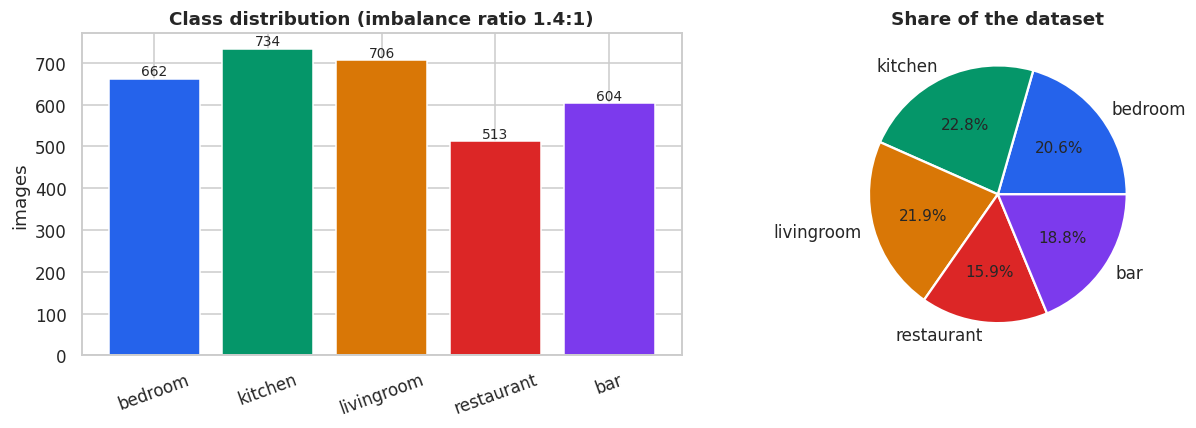

class
bedroom       662
kitchen       734
livingroom    706
restaurant    513
bar           604

Total usable images : 3,219
Imbalance ratio     : 1.43 : 1  (kitchen vs restaurant)


In [7]:
counts = manifest["class"].value_counts().reindex(CLASS_NAMES)
imbalance_ratio = counts.max() / counts.min()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bars = axes[0].bar(counts.index, counts.values, color=PALETTE)
axes[0].set_title(f"Class distribution (imbalance ratio {imbalance_ratio:.1f}:1)")
axes[0].set_ylabel("images")
axes[0].tick_params(axis="x", rotation=20)
for bar, value in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 8, f"{value:,}", ha="center", fontsize=9)

axes[1].pie(
    counts.values, labels=counts.index, autopct="%1.1f%%", colors=PALETTE,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)
axes[1].set_title("Share of the dataset")
plt.tight_layout()
plt.show()

print(counts.to_string())
print(f"\nTotal usable images : {len(manifest):,}")
print(f"Imbalance ratio     : {imbalance_ratio:.2f} : 1  ({counts.idxmax()} vs {counts.idxmin()})")

**What I take from the imbalance.** The classes are not uniform — `kitchen` (734) has roughly 1.4 times as
many images as `restaurant` (513) — but the imbalance is **mild by construction**, because the
400-image floor applied in §1 excluded the genuinely rare categories. This is the situation Week 8
warns about in a manageable form: a model can still improve its average loss by under-predicting
the smallest class, but far less than it could with a steeper spread. Two consequences
follow, and I apply both later:

* **Stratified splitting** (§5) so train, validation and test all carry the same class proportions.
* **Class weights** (§8) so the loss does not let the model ignore the minority room, and
  **macro-averaged** F1 (§12) as the headline metric rather than plain accuracy.

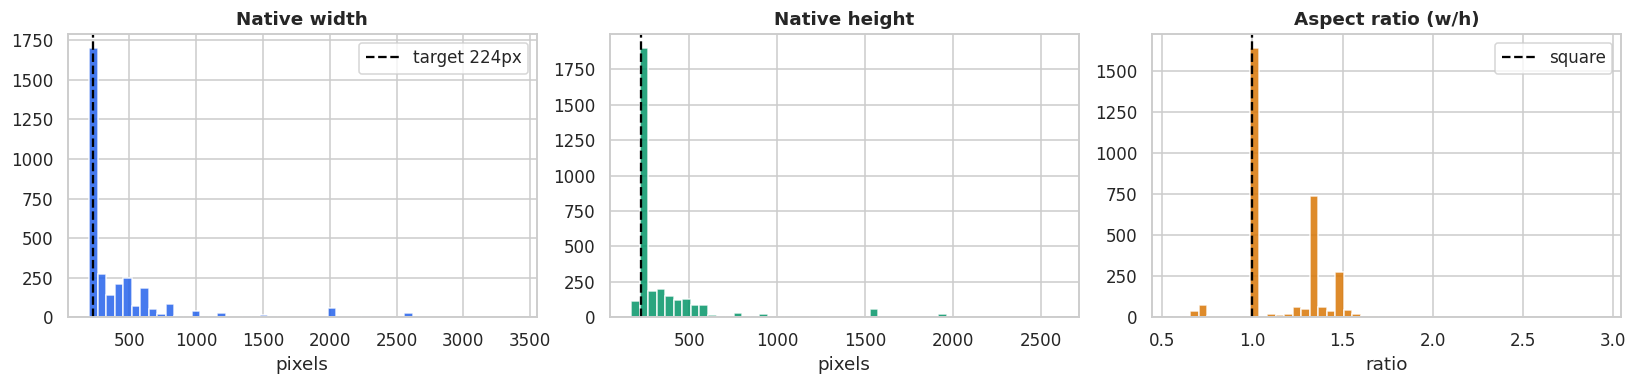

         width   height   aspect       kb
count  3219.00  3219.00  3219.00  3219.00
mean    446.94   374.89     1.16   172.60
std     403.11   301.04     0.24   418.32
min     200.00   171.00     0.56     6.95
25%     256.00   256.00     1.00    46.82
50%     256.00   256.00     1.00    62.85
75%     500.00   370.50     1.33   105.14
max    3389.00  2592.00     2.92  5093.09

Images at least 224px on the short side: 95.7%


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

axes[0].hist(manifest["width"], bins=50, color=PALETTE[0], alpha=0.85)
axes[0].axvline(CFG.img_size[0], color="black", ls="--", lw=1.5,
                label=f"target {CFG.img_size[0]}px")
axes[0].set_title("Native width"); axes[0].set_xlabel("pixels"); axes[0].legend()

axes[1].hist(manifest["height"], bins=50, color=PALETTE[1], alpha=0.85)
axes[1].axvline(CFG.img_size[1], color="black", ls="--", lw=1.5)
axes[1].set_title("Native height"); axes[1].set_xlabel("pixels")

axes[2].hist(manifest["aspect"], bins=50, color=PALETTE[2], alpha=0.85)
axes[2].axvline(1.0, color="black", ls="--", lw=1.5, label="square")
axes[2].set_title("Aspect ratio (w/h)"); axes[2].set_xlabel("ratio"); axes[2].legend()

plt.tight_layout(); plt.show()

print(manifest[["width", "height", "aspect", "kb"]].describe().round(2).to_string())
pct_above_target = (manifest[["width", "height"]].min(axis=1) >= CFG.img_size[0]).mean() * 100
print(f"\nImages at least {CFG.img_size[0]}px on the short side: {pct_above_target:.1f}%")

**What I take from the geometry.** Most images are comfortably larger than 224 px on the short side, so
resizing to 224×224 is predominantly *downsampling* — I lose fine detail but invent nothing. The
aspect ratios cluster around 4:3 landscape with a long tail, which is why §6 resizes directly to a
square rather than centre-cropping: a centre crop on a 2:1 panorama would discard half the room,
and in scene recognition the discriminative evidence (a hob, a bath, a bed) is often off-centre.
The mild horizontal squash this introduces is a distortion the model can learn around, and it is
applied identically at training and inference time, so it is consistent rather than harmful.

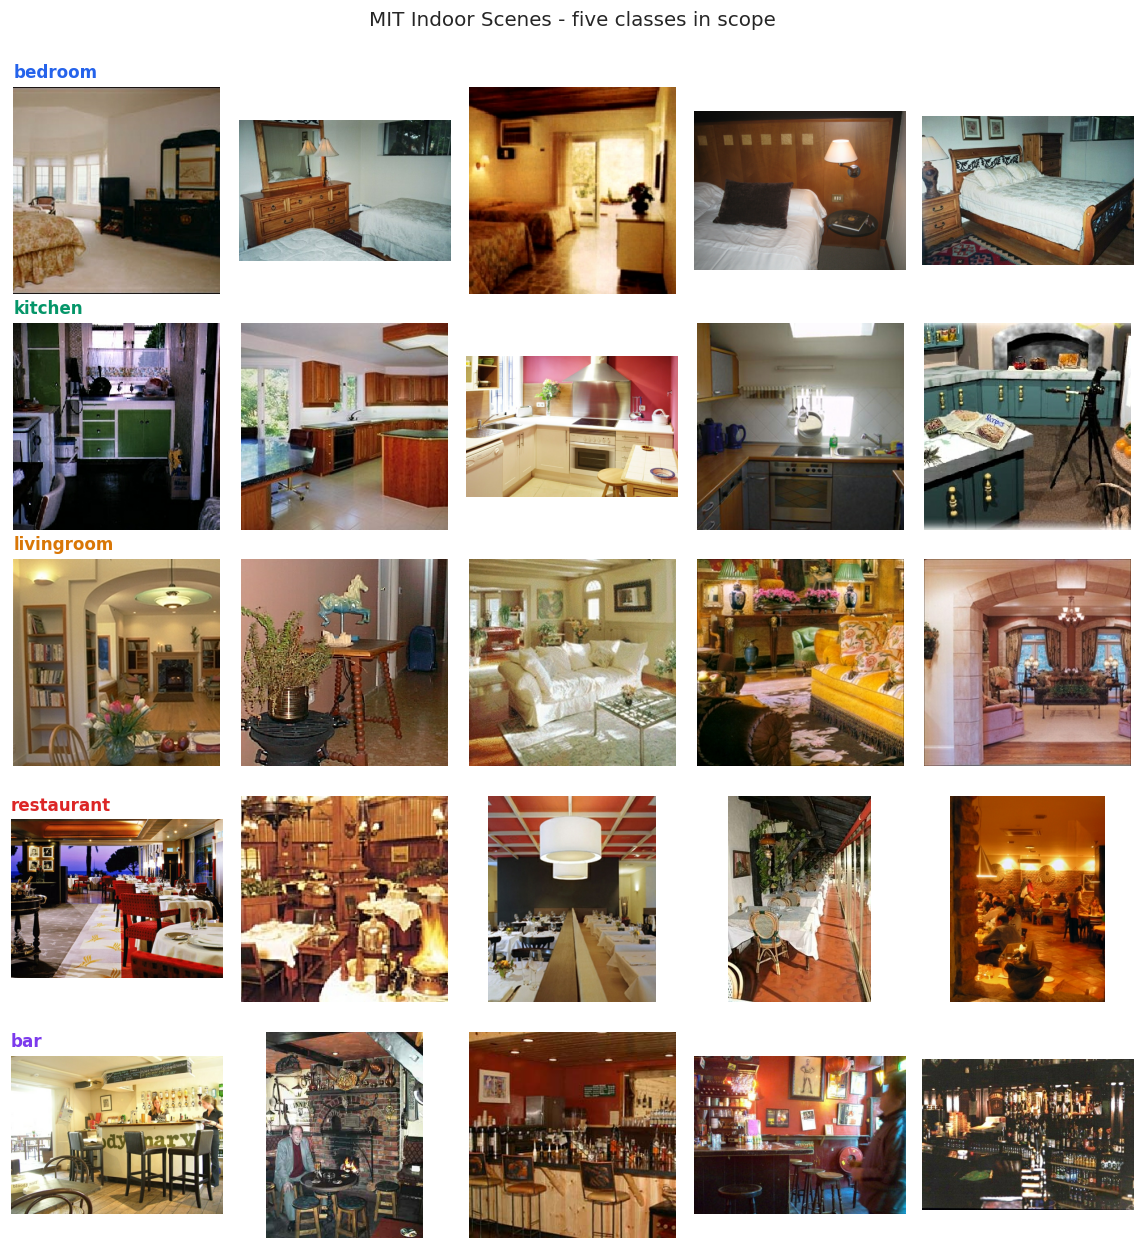

In [9]:
def show_samples(df: pd.DataFrame, n_per_class: int = 5, title: str = "Sample images") -> None:
    """Grid of random examples, one row per class."""
    fig, axes = plt.subplots(
        len(CLASS_NAMES), n_per_class, figsize=(2.1 * n_per_class, 2.25 * len(CLASS_NAMES))
    )
    rng = np.random.default_rng(SEED)
    for row, cls in enumerate(CLASS_NAMES):
        subset = df[df["class"] == cls]
        picks = rng.choice(subset["path"].values, size=min(n_per_class, len(subset)), replace=False)
        for col in range(n_per_class):
            ax = axes[row, col]
            ax.axis("off")
            if col < len(picks):
                img = tf.io.decode_image(tf.io.read_file(picks[col]), channels=3,
                                         expand_animations=False)
                ax.imshow(img.numpy())
            if col == 0:
                ax.set_title(cls, loc="left", fontsize=11, color=PALETTE[row])
    fig.suptitle(title, fontsize=13, y=1.005)
    plt.tight_layout(); plt.show()


show_samples(manifest, n_per_class=5, title="MIT Indoor Scenes - five classes in scope")

**What the samples tell me.** Three difficulties are visible immediately, and they line up with
the brief's list of prototype failures:

* **Within-class variation is enormous.** `kitchen` spans cramped galley kitchens and open-plan
  islands; `bedroom` spans hotel rooms and children's rooms. I need the model to learn *function*, not
  a single visual template.
* **Between-class variation is sometimes tiny.** `restaurant` and `bar` share tables, seating,
  bottles, low lighting and crowd density; often only the presence of a serving counter or laid
  place settings separates them, and those cues are frequently partly out of frame.
* **Lighting and viewpoint are wildly inconsistent** — exactly what §7's augmentation targets.

---
## 5. Stratified splitting (leakage-safe)

I make the split **once, at file level, before anything is loaded**, and train and evaluate both
models on exactly these three sets. That is the precondition for the comparison in
§13 to mean anything at all (Week 7: *"Same data split — train, validation and test must be
identical"*).

**70 / 15 / 15**, stratified by class:

* **Train (70%)** — weight updates only.
* **Validation (15%)** — early stopping, learning-rate scheduling, and every design decision.
* **Test (15%)** — held out, and used exactly once, in §12. I choose no hyperparameter from it.

Splitting on the *file list* rather than on loaded tensors guarantees no image can appear in two
splits, and fixing the seed makes my partition reproducible across runs and across models.

*Note on the official protocol.* The dataset ships `TrainImages.txt` / `TestImages.txt` defining
the canonical 80-train / 20-test images per class. That protocol is designed for the full 67-class
benchmark and would leave only ~100 images per class here, discarding roughly 80% of the available
data and making the per-class metrics extremely noisy. Since this is an applied build rather than a
benchmark submission, a stratified 70/15/15 over all usable images is the better trade — at the
cost of not being directly comparable to published MIT Indoor leaderboard numbers.

Train 2,253 | Val 483 | Test 483
No leakage between splits (asserted).

            train  val  test  total
class                              
bedroom       463   99   100    662
kitchen       514  110   110    734
livingroom    494  106   106    706
restaurant    359   77    77    513
bar           423   91    90    604
TOTAL        2253  483   483   3219


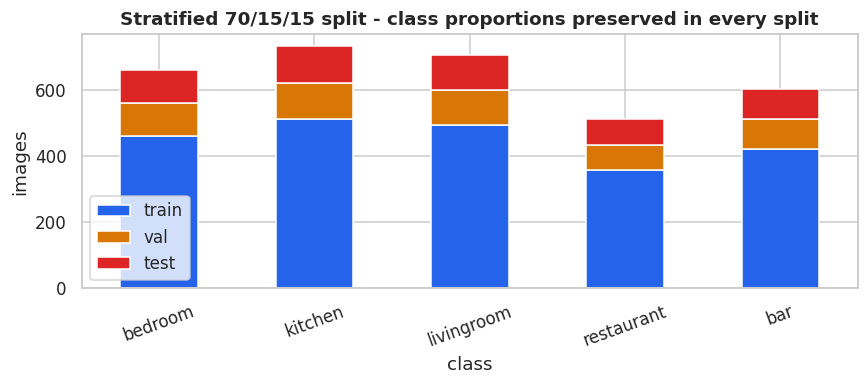

In [10]:
train_df, temp_df = train_test_split(
    manifest,
    test_size=CFG.test_frac + CFG.val_frac,
    stratify=manifest["label"],
    random_state=SEED,
    shuffle=True,
)
# Split the held-back portion evenly into validation and test, again stratified.
val_df, test_df = train_test_split(
    temp_df,
    test_size=CFG.test_frac / (CFG.test_frac + CFG.val_frac),
    stratify=temp_df["label"],
    random_state=SEED,
    shuffle=True,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# --- Leakage assertion: no file may appear in more than one split -------------------------------
_sets = [set(d["path"]) for d in (train_df, val_df, test_df)]
assert not (_sets[0] & _sets[1]), "Leak: train/val overlap"
assert not (_sets[0] & _sets[2]), "Leak: train/test overlap"
assert not (_sets[1] & _sets[2]), "Leak: val/test overlap"
assert sum(len(s) for s in _sets) == len(manifest), "Split does not partition the manifest"

split_table = pd.DataFrame(
    {
        "train": train_df["class"].value_counts(),
        "val": val_df["class"].value_counts(),
        "test": test_df["class"].value_counts(),
    }
).reindex(CLASS_NAMES)
split_table["total"] = split_table.sum(axis=1)
split_table.loc["TOTAL"] = split_table.sum()

print(f"Train {len(train_df):,} | Val {len(val_df):,} | Test {len(test_df):,}")
print("No leakage between splits (asserted).\n")
print(split_table.to_string())

ax = split_table.drop(index="TOTAL")[["train", "val", "test"]].plot(
    kind="bar", stacked=True, figsize=(8, 3.6), color=[PALETTE[0], PALETTE[2], PALETTE[3]]
)
ax.set_title("Stratified 70/15/15 split - class proportions preserved in every split")
ax.set_ylabel("images"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 5.1 Balancing the training set to a common size

§4 measured a mild 1.4:1 imbalance: `kitchen` has 734 images, `restaurant` 513. After the 70/15/15
split the training portion ranges from roughly 513 down to 359 images per class. I therefore **resample the training set to a fixed number of images per class** — majority classes are randomly
**down-sampled**, minority classes are **up-sampled with replacement**.

#### The 1.5× duplication ceiling

I did not pick 500 arbitrarily. It is the largest round number that keeps **every** class within
the **1.5× duplication** ceiling I set myself: the smallest training class (`restaurant`,
359 images) reaches 500 at 1.39×, and the largest (`kitchen`, 513) is down-sampled rather than
duplicated. Had `bathroom` and `dining_room` been retained, the same target would have demanded
3.65× and 2.62× — each of their images repeated three or four times per epoch, which is precisely
the memorisation risk described below. My class selection in §1 and this balancing target are therefore
one joint decision, not two independent ones.

#### Why this happens *after* the split, and only to the training set

This ordering is the single most important thing I got right in this section. Up-sampling duplicates rows; if
it were applied to the full dataset *before* splitting, copies of the same photograph would land in
both the training and the test set. The model would then be tested on images it had memorised, and
the reported accuracy would be meaningless — inflated by an amount nobody could measure after the
fact. This is one of the most common and most damaging errors in applied machine learning.

I therefore leave validation and test **completely untouched**, at the dataset's true class
distribution. They represent the real world, in which restaurants are genuinely less common in the
data than kitchens, and a model that only performs well on an artificially balanced test set would
tell me nothing. An explicit assertion below confirms no training file — original or duplicated —
appears in either held-out split.

#### What duplication does and does not buy

Up-sampling `restaurant` to the target repeats some of its 359 training images once. Those
duplicates are **not identical in practice**: the augmentation block from §7 applies a fresh random
brightness, rotation, zoom and translation to every image on every epoch, so each copy is seen as a
different view of the same room. Resampling supplies the *frequency*; augmentation supplies the
*variety*.

I keep every original image exactly once before drawing any duplicate, so up-sampling can never
discard a real photograph in favour of a copy of another — an assertion below enforces this.

It remains a trade-off, and I say so in my report. The underlying information content of the
smaller classes does not increase, so the risk of memorising particular rooms rises, and §14's
per-class recall is where that would become visible. Down-sampling `kitchen` likewise discards 13
real images that were available. Both costs are modest at a ceiling of 1.39×, which is the whole
reason I set it. I accept them in exchange for a training signal in which no class
dominates the loss.

Training set balanced to 500 images per class (2,253 -> 2,500 rows)

            original  after        action  duplication factor  distinct images
class                                                                         
bedroom          463    500    up-sampled                1.08              463
kitchen          514    500  down-sampled                0.97              514
livingroom       494    500    up-sampled                1.01              494
restaurant       359    500    up-sampled                1.39              359
bar              423    500    up-sampled                1.18              423

No balanced-train file appears in validation or test (asserted).
Distinct images used for training: 2,239 of 2,253 available (2,500 draws after resampling)


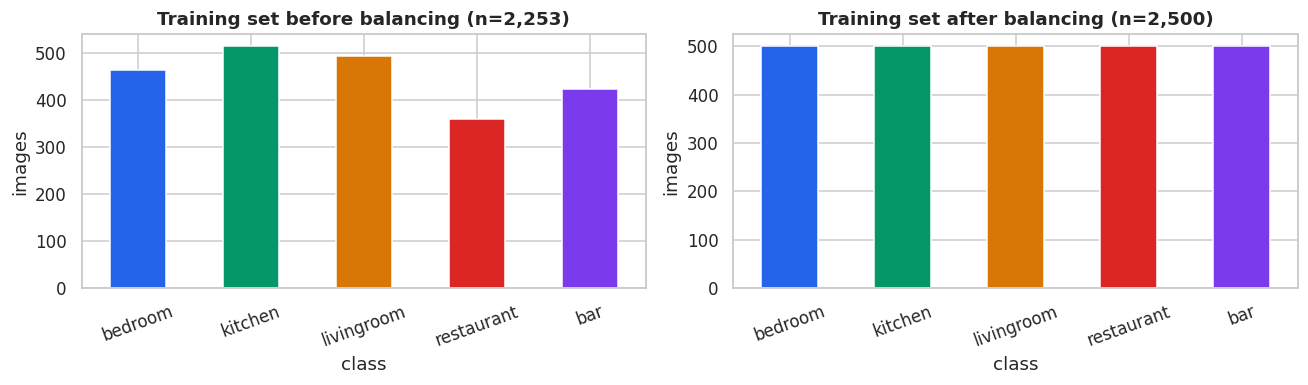

In [11]:
def balance_training_set(df: pd.DataFrame, target: int, seed: int = SEED) -> pd.DataFrame:
    """Resample a training manifest to `target` rows per class.

    Classes above the target are down-sampled without replacement; classes below it are up-sampled
    with replacement. Applied to the TRAINING split only - never to validation or test.
    """
    rng = np.random.RandomState(seed)
    frames, report = [], []
    for cls in CFG.classes:
        subset = df[df["class"] == cls]
        have = len(subset)
        if have >= target:
            picked = subset.sample(n=target, replace=False, random_state=rng)
            action = "down-sampled"
        else:
            # Keep every original image exactly once, then draw only the shortfall with
            # replacement. Sampling the whole target with replacement would, by chance, omit some
            # originals entirely - discarding real images while duplicating others, which is the
            # opposite of what up-sampling is for.
            extra = subset.sample(n=target - have, replace=True, random_state=rng)
            picked = pd.concat([subset, extra])
            action = "up-sampled"
        frames.append(picked)
        report.append({
            "class": cls,
            "original": have,
            "after": target,
            "action": action,
            "duplication factor": round(target / have, 2) if have else float("nan"),
            "distinct images": subset["path"].nunique(),
        })
    balanced = pd.concat(frames).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return balanced, pd.DataFrame(report).set_index("class")


if CFG.balance_train_to:
    train_balanced_df, balance_report = balance_training_set(train_df, CFG.balance_train_to)
    print(f"Training set balanced to {CFG.balance_train_to} images per class "
          f"({len(train_df):,} -> {len(train_balanced_df):,} rows)\n")
    print(balance_report.to_string())

    # --- Leakage assertion: nothing in the balanced training set may appear in val or test -------
    _train_files = set(train_balanced_df["path"])
    assert not (_train_files & set(val_df["path"])), "Leak: balanced train overlaps validation"
    assert not (_train_files & set(test_df["path"])), "Leak: balanced train overlaps test"
    assert train_balanced_df["path"].nunique() <= len(train_df), "Balancing introduced unseen files"

    # Every up-sampled class must retain all of its original images; only down-sampled classes
    # may lose any. This is what distinguishes "duplicate to fill" from "resample and hope".
    for cls in CFG.classes:
        original = set(train_df[train_df["class"] == cls]["path"])
        kept = set(train_balanced_df[train_balanced_df["class"] == cls]["path"])
        if len(original) <= CFG.balance_train_to:
            assert kept == original, f"{cls}: up-sampling dropped {len(original - kept)} originals"

    print("\nNo balanced-train file appears in validation or test (asserted).")
    print(f"Distinct images used for training: {train_balanced_df['path'].nunique():,} "
          f"of {train_df['path'].nunique():,} available "
          f"({len(train_balanced_df):,} draws after resampling)")
else:
    train_balanced_df = train_df
    print("Balancing disabled; using the stratified training split unchanged.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
train_df["class"].value_counts().reindex(CLASS_NAMES).plot(
    kind="bar", ax=axes[0], color=PALETTE)
axes[0].set_title(f"Training set before balancing (n={len(train_df):,})")
train_balanced_df["class"].value_counts().reindex(CLASS_NAMES).plot(
    kind="bar", ax=axes[1], color=PALETTE)
axes[1].set_title(f"Training set after balancing (n={len(train_balanced_df):,})")
for ax in axes:
    ax.set_ylabel("images"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

---
## 6. Input pipeline: resize, normalise, batch, prefetch

One pipeline, built once, reused by both my models — the *"build it once as reusable code"*
instruction from Week 8.

### My one deliberate design decision: normalisation lives *inside* the model

The `tf.data` pipeline deliberately stops at **resized `uint8` pixels in [0, 255]**. It does not
normalise. Each model instead begins with its own scaling layer:

| Model | First layer | Why |
|---|---|---|
| CNN from scratch | `Rescaling(1/255)` → [0, 1] | small values train a fresh network better |
| MobileNetV2 | `mobilenet_v2.preprocess_input` → [−1, 1] | the scaling it was pre-trained with |

This is the single most common silent failure in transfer learning (Week 7): feed a backbone the
wrong input range and accuracy quietly collapses with no error message. Binding each model to its
own correct preprocessing makes that mistake structurally impossible, while still letting both
share one identical data pipeline — so the comparison stays fair *and* every model is fed correctly.

A second benefit: preprocessing travels *with* the exported model (§16), so a deployed HomeVision
camera cannot get the scaling wrong either.

### Efficiency

`cache()` holds decoded images in memory after the first epoch (≈375 MB as `uint8` — cheap),
`shuffle()` re-randomises order every epoch, and `prefetch(AUTOTUNE)` prepares the next batch while
the current one trains, so the GPU is never left waiting on disk.

In [12]:
AUTOTUNE = tf.data.AUTOTUNE


def decode_and_resize(path: tf.Tensor, label: tf.Tensor):
    """Read a file, decode to 3-channel RGB, resize to the target square, keep as uint8."""
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, CFG.img_size, method="bilinear")
    # Cache as uint8: 4x less memory than float32, and the models rescale anyway.
    return tf.cast(tf.round(img), tf.uint8), label


def make_dataset(df: pd.DataFrame, training: bool, batch_size: int = CFG.batch_size) -> tf.data.Dataset:
    """Build a tf.data pipeline from a split manifest.

    Augmentation is NOT applied here - it lives inside the models (section 7) so that it is
    automatically inactive at validation and inference time.
    """
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label"].values.astype("int32"))
    )
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if training:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    # Models expect float input; the cast is cheap and happens per batch.
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(train_balanced_df, training=True)   # balanced in section 5.1
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

xb, yb = next(iter(train_ds))
print(f"Batch images : {xb.shape}  dtype={xb.dtype}  range=[{xb.numpy().min():.0f}, {xb.numpy().max():.0f}]")
print(f"Batch labels : {yb.shape}  dtype={yb.dtype}  values={sorted(set(yb.numpy().tolist()))}")
print(f"\nBatches -> train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

Batch images : (32, 224, 224, 3)  dtype=<dtype: 'float32'>  range=[0, 255]
Batch labels : (32,)  dtype=<dtype: 'int32'>  values=[0, 1, 2, 3, 4]

Batches -> train 79 | val 16 | test 16


---
## 7. Data augmentation — chosen against the brief's failure modes

I did not treat augmentation as a box to tick. The brief lists the exact conditions under which the HomeVision
prototype fails, and **I chose each augmentation below to simulate one of them** (Week 8:
*"Choosing augmentations deliberately — and saying why — is worth marks"*).

| Brief's stated failure mode | Augmentation | Setting | Justification |
|---|---|---|---|
| Variations in **lighting conditions** | `RandomBrightness` | ±20% | A room at noon, at dusk and under one lamp must map to the same class. The widest realistic range a camera sees. |
| Variations in **lighting / contrast** | `RandomContrast` | ±20% | Backlit windows and auto-exposure produce large contrast swings. |
| **Camera angles** | `RandomRotation` | ±10% (±36°) | Wall and ceiling mounts are rarely perfectly level. Kept modest — a 90° rotation is not something a fixed camera ever produces. |
| **Camera angles** (mirrored rooms) | `RandomFlip("horizontal")` | — | Apartment layouts are frequently mirror images of each other. Horizontal only: a vertical flip would put the ceiling on the floor, which is not label-preserving for indoor scenes. |
| **Furniture arrangement / framing** | `RandomZoom` | ±15% | Different mounting distances and focal lengths change how much of the room is in frame. |
| **Cluttered scenes / object position** | `RandomTranslation` | ±10% | Shifts the discriminative object (hob, bath, bed) away from centre, discouraging reliance on position. |

**What I deliberately left out.** No vertical flip (not label-preserving indoors), no shear, no
channel shuffle, and no rotation beyond ±36° — Week 8's rule of thumb is to *"only invent
variations the real camera could actually produce"*. Inventing impossible images wastes capacity
on a distribution that will never be served.

**Applied to training only.** I put the augmentation block *inside* each model as Keras layers. Keras runs these layers only when `training=True`, so validation and test evaluation
automatically see clean, unaugmented images — the guarantee Week 8 asks for, enforced by
construction rather than by remembering to switch a flag.

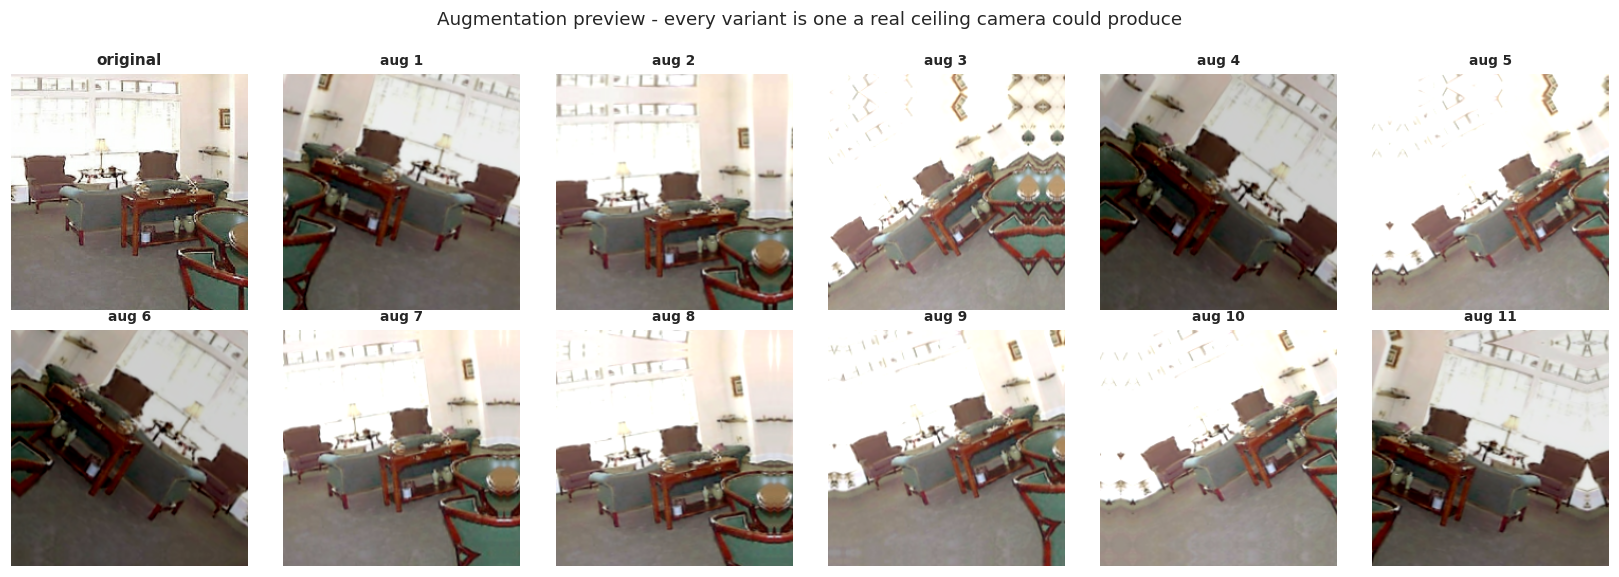

In [13]:
def build_augmentation(name: str = "augmentation") -> keras.Sequential:
    """Augmentation block, mapped one-to-one onto the brief's stated failure modes."""
    return keras.Sequential(
        [
            layers.RandomFlip("horizontal", seed=SEED),        # mirrored apartment layouts
            layers.RandomRotation(0.10, fill_mode="reflect", seed=SEED),      # camera tilt
            layers.RandomZoom(0.15, fill_mode="reflect", seed=SEED),          # mounting distance
            layers.RandomTranslation(0.10, 0.10, fill_mode="reflect", seed=SEED),  # clutter/position
            layers.RandomBrightness(0.20, value_range=(0, 255), seed=SEED),   # lighting
            layers.RandomContrast(0.20, seed=SEED),                            # exposure swings
        ],
        name=name,
    )


# --- Visual check: what the model will actually be trained on ------------------------------------
_aug = build_augmentation("augmentation_preview")
sample = xb[:1]

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
axes[0, 0].imshow(sample[0].numpy().astype("uint8")); axes[0, 0].set_title("original", fontsize=10)
axes[0, 0].axis("off")
for idx in range(1, 12):
    ax = axes[idx // 6, idx % 6]
    aug_img = _aug(sample, training=True)[0].numpy()
    ax.imshow(np.clip(aug_img, 0, 255).astype("uint8"))
    ax.set_title(f"aug {idx}", fontsize=9)
    ax.axis("off")
fig.suptitle("Augmentation preview - every variant is one a real ceiling camera could produce",
             fontsize=12, y=1.0)
plt.tight_layout(); plt.show()

---
## 8. Class imbalance — and why the weights are now neutral

§4 measured a mild 1.43:1 imbalance between the largest and smallest class. Left alone, the loss
is dominated by `kitchen` and `livingroom`, and the model can lower its average loss by
systematically under-predicting `restaurant`.

There are two standard remedies, and **I would be wrong to apply both at once**:

| Remedy | Mechanism | Status here |
|---|---|---|
| **Resampling** | Change how *often* each class is seen | **Used** — §5.1 resamples the training set to an equal count per class |
| **Class weighting** | Change how *much* each example counts in the loss | Computed below, but now neutral by construction |

Because §5.1 has already equalised the class counts, scikit-learn's *balanced* heuristic
(`n_samples / (n_classes × n_samples_in_class)`) evaluates to approximately **1.0 for every
class**. I therefore compute the weights on the **balanced** training frame rather than the original one, and the table below should show a flat column.

This is deliberate on my part. Computing the weights on the *original* distribution while also resampling
would correct the same imbalance twice: `restaurant` would be both seen more often *and* weighted
more heavily per example, over-correcting it into a class the model over-predicts. Keeping the
calculation visible — rather than deleting it — shows I made this decision rather than forgot it, and leaves the mechanism in place should `CFG.balance_train_to` be set to 0.

Whichever path is active, it is identical for both models, so it is not a confound in §13.

In [14]:
# Computed on the BALANCED frame (see the note above): resampling has already equalised the
# classes, so weighting on the original counts would correct the same imbalance a second time.
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(CFG.n_classes),
    y=train_balanced_df["label"].values,
)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(class_weights_array)}

weight_table = pd.DataFrame(
    {
        "original train images": train_df["class"].value_counts().reindex(CLASS_NAMES).values,
        "after balancing": train_balanced_df["class"].value_counts().reindex(CLASS_NAMES).values,
        "class weight": np.round(class_weights_array, 3),
    },
    index=CLASS_NAMES,
)
print(weight_table.to_string())

spread = class_weights_array.max() / class_weights_array.min()
if spread < 1.01:
    print(f"\nWeights are uniform (spread {spread:.3f}x) - resampling in section 5.1 has already")
    print("equalised the classes, so the loss needs no further correction.")
else:
    print(f"\nMinority class '{counts.idxmin()}' is up-weighted {spread:.2f}x relative to the "
          f"majority class.")

            original train images  after balancing  class weight
bedroom                       463              500           1.0
kitchen                       514              500           1.0
livingroom                    494              500           1.0
restaurant                    359              500           1.0
bar                           423              500           1.0

Weights are uniform (spread 1.000x) - resampling in section 5.1 has already
equalised the classes, so the loss needs no further correction.


---
## 9. Model design and shared training protocol

I train two models, which is what the brief asks for, and I chose them so the pair forms a
**controlled comparison rather than an arbitrary pairing**:

| | Model A | Model B |
|---|---|---|
| **Architecture** | Custom CNN | MobileNetV2 |
| **Weights** | random initialisation | ImageNet |
| **Question it answers** | What can be learned from ~2,250 distinct images alone? | Does transfer learning help, and by how much? |
| **Role** | honest baseline | the edge-deployment candidate |

A → B isolates exactly one variable: **pre-training**. Everything else — split, pipeline,
augmentation, class weights, epoch budget, early-stopping rule, optimiser family and test set — is
held constant, which is precisely the fairness checklist from Week 7. A difference between the two
is therefore down to the ImageNet weights and nothing else.

A **second** controlled comparison follows in §11.3, where the augmentation strategy is ablated
under a fixed budget. Between them, the notebook measures the two design decisions that actually
drive the result, rather than reporting a leaderboard of architectures.

### Shared training protocol (identical for both)

| Setting | Value | Justification |
|---|---|---|
| Optimiser | Adam | Adaptive per-parameter rates; the robust default from Week 4, and it removes hand-tuned momentum as a confound between models. |
| Loss | `sparse_categorical_crossentropy` | Labels are integers, so sparse CE matches the label format directly (Week 8) — no one-hot expansion needed. |
| Stage 1 | ≤30 epochs @ 1e-3 | Trains the head / the whole from-scratch net to convergence. |
| Stage 2 | ≤15 epochs, reduced LR | Fine-tuning for B and C; continued training for A. |
| Total budget | ≤45 epochs | **The same for every model** — no model gets a longer race. |
| Early stopping | `val_loss`, patience 6, restore best weights | Stops each model when *it* stops improving, so the budget is a ceiling rather than a mandate. Best weights are restored, so the reported model is never the overfitted final epoch. |
| LR schedule | `ReduceLROnPlateau` ×0.5, patience 3 | Lets each model escape a plateau without manual babysitting. |
| Class weights | balanced (§8) | Same weights for both. |
| Checkpointing | one run-wide best, restored before evaluation | `restore_best_weights` only looks *inside one stage*. If fine-tuning degrades a model, the stage-2 best can be worse than the stage-1 best — and I would then be reporting the degraded model. A single checkpoint spanning both stages means every model is evaluated at its own best. |

**On stage-2 learning rates.** Models B and C fine-tune at **1e-5**, because their weights are
already good and a normal rate would destroy them (Week 7). Model A fine-tunes at **1e-4**: it has
no pre-trained knowledge to protect, so 1e-5 would merely waste its budget doing nothing. What
fairness requires is an equal *budget* and an equal *stopping rule*, not an identical number that
means two different things in two different settings — and both are held equal here.

In [15]:
class ClipToValueRange(layers.Layer):
    """Clamp augmented pixels back into [0, 255].

    RandomBrightness and RandomContrast can push values outside the valid range; each backbone's
    preprocess_input assumes a clean 0-255 input, so we restore it explicitly.
    """

    def __init__(self, vmin: float = 0.0, vmax: float = 255.0, **kwargs):
        super().__init__(**kwargs)
        self.vmin, self.vmax = vmin, vmax

    def call(self, inputs):
        return tf.clip_by_value(inputs, self.vmin, self.vmax)

    def get_config(self):
        return {**super().get_config(), "vmin": self.vmin, "vmax": self.vmax}


class ModelSpec:
    """Bundles a model with everything the evaluation, Grad-CAM and export sections need."""

    def __init__(self, name, model, preprocess_fn=None, base=None,
                 last_conv=None, head_layers=(), colour="#2563eb"):
        self.name = name
        self.model = model
        self.preprocess_fn = preprocess_fn          # None for the from-scratch CNN
        self.base = base                            # nested backbone, or None
        self.last_conv = last_conv                  # layer name, flat models only
        self.head_layers = list(head_layers)        # layer names after the backbone
        self.colour = colour
        self.histories = {}                         # stage name -> keras History
        self.train_seconds = 0.0
        self.results = {}                           # filled in by section 12
        self.best_val_loss = float("inf")           # best across ALL stages, not just the last
        self.checkpoint = os.path.join(CFG.work_dir, f"{name}.best.weights.h5")

    @property
    def total_params(self) -> int:
        return int(self.model.count_params())

    @property
    def trainable_params(self) -> int:
        return int(sum(np.prod(w.shape) for w in self.model.trainable_weights))


REGISTRY: dict[str, ModelSpec] = {}


def make_callbacks(spec: ModelSpec, monitor: str = "val_loss") -> list:
    """Identical callback stack for every model and every stage.

    The checkpoint path is per *model*, not per stage, and stage 2 is seeded with stage 1's best
    score via `initial_value_threshold`. That makes the saved checkpoint the best weights across
    the whole run - see `restore_global_best` below for why that matters.
    """
    return [
        keras.callbacks.EarlyStopping(
            monitor=monitor, patience=CFG.es_patience,
            restore_best_weights=True, verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor=monitor, factor=0.5, patience=CFG.rlrop_patience,
            min_lr=1e-7, verbose=1,
        ),
        keras.callbacks.ModelCheckpoint(
            spec.checkpoint, monitor=monitor, save_best_only=True,
            save_weights_only=True, verbose=0,
            initial_value_threshold=spec.best_val_loss,   # carry the bar over from stage 1
        ),
    ]


def train_stage(spec: ModelSpec, stage: str, epochs: int, lr: float) -> keras.callbacks.History:
    """Compile and fit one stage, recording wall-clock time in the spec."""
    spec.model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    trainable = spec.trainable_params
    print(f"\n{'=' * 78}\n{spec.name} - {stage}\n"
          f"  epochs<= {epochs} | lr {lr:g} | trainable params {trainable:,}\n{'=' * 78}")

    started = time.time()
    history = spec.model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=CLASS_WEIGHTS,
        callbacks=make_callbacks(spec),
        verbose=1,
    )
    elapsed = time.time() - started
    spec.train_seconds += elapsed
    spec.histories[stage] = history

    best_val = min(history.history["val_loss"])
    best_acc = max(history.history["val_accuracy"])
    spec.best_val_loss = min(spec.best_val_loss, best_val)
    print(f"\n  {stage} done in {elapsed / 60:.1f} min over {len(history.history['loss'])} epochs"
          f"  |  best val_loss {best_val:.4f}  best val_acc {best_acc:.4f}")
    return history


def restore_global_best(spec: ModelSpec) -> None:
    """Load the best weights seen across BOTH stages.

    `EarlyStopping(restore_best_weights=True)` only restores the best epoch *within the stage it
    ran in*. If fine-tuning makes a model worse - which it can, and which is exactly what we are
    measuring - the model left in memory after stage 2 would be worse than the one stage 1 already
    produced, and we would report that degraded model as the result. Reloading the run-wide
    checkpoint guarantees each model is evaluated at its own best.
    """
    if os.path.exists(spec.checkpoint):
        spec.model.load_weights(spec.checkpoint)
        print(f"Restored {spec.name} to its best weights across all stages "
              f"(val_loss {spec.best_val_loss:.4f}).")
    else:
        print(f"No checkpoint found for {spec.name}; keeping the in-memory weights.")


def plot_history(spec: ModelSpec) -> None:
    """Accuracy and loss curves, with the stage boundary marked."""
    stages = list(spec.histories.keys())
    acc, val_acc, loss, val_loss, boundaries = [], [], [], [], []
    for stage in stages:
        h = spec.histories[stage].history
        acc += h["accuracy"]; val_acc += h["val_accuracy"]
        loss += h["loss"]; val_loss += h["val_loss"]
        boundaries.append(len(acc))

    epochs_axis = range(1, len(acc) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs_axis, acc, label="train", color=spec.colour, lw=1.8)
    axes[0].plot(epochs_axis, val_acc, label="validation", color=spec.colour, lw=1.8, ls="--")
    axes[0].set_title(f"{spec.name} - accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()

    axes[1].plot(epochs_axis, loss, label="train", color=spec.colour, lw=1.8)
    axes[1].plot(epochs_axis, val_loss, label="validation", color=spec.colour, lw=1.8, ls="--")
    axes[1].set_title(f"{spec.name} - loss"); axes[1].set_xlabel("epoch"); axes[1].legend()

    for ax in axes:
        for boundary in boundaries[:-1]:
            ax.axvline(boundary + 0.5, color="grey", ls=":", lw=1.4)
            ax.text(boundary + 0.7, ax.get_ylim()[1] * 0.97, "stage 2",
                    fontsize=8, color="grey", va="top")
    plt.tight_layout(); plt.show()

    gap = acc[-1] - val_acc[-1]
    print(f"Final train-validation accuracy gap: {gap:+.3f} "
          f"({'overfitting' if gap > 0.12 else 'well controlled'})")

## 10. Model A — CNN from scratch (baseline)

**Why I built it.** To establish honestly what ~2,250 distinct training images achieve with no outside knowledge.
Without this number, a transfer-learning result has nothing to be better *than*.

**Architecture.** Four convolutional blocks, doubling filters 32 → 64 → 128 → 256, each block
`Conv2D → BatchNorm → ReLU → Conv2D → BatchNorm → ReLU → MaxPool`, then global average pooling and
a small dense head.

| Choice | Justification |
|---|---|
| **3×3 kernels, stacked in pairs** | Two stacked 3×3 layers cover the same receptive field as one 5×5 with fewer parameters and an extra non-linearity — the VGG insight from Week 6. |
| **Doubling filters as resolution halves** | Keeps compute roughly constant per block while capacity shifts from many-positions/few-features to few-positions/many-features — the standard pyramid. |
| **Batch normalisation after every conv** | Stabilises and accelerates training and adds mild regularisation (Week 4). Essential here: without it a 4-block net trained on this little data is slow to converge. |
| **Global average pooling instead of `Flatten`** | `Flatten` on a 14×14×256 map into a dense layer would add ~6.4M parameters — more than the entire convolutional stack — and is where a small-data CNN overfits hardest. GAP has zero parameters and forces each channel to be a genuine whole-image feature detector. |
| **Dropout 0.3 before the classifier** | The dataset is small and the network deep enough to memorise it; dropout is the cheapest counter (Week 4). |
| **Softmax over 5 units** | Multi-class, mutually exclusive rooms; pairs with sparse categorical cross-entropy. |

Augmentation and `Rescaling(1/255)` are the first layers *inside* the model, so the scaling
travels with the exported artefact and augmentation is automatically training-only.

In [16]:
def build_scratch_cnn(name: str = "CNN_from_scratch") -> ModelSpec:
    """A compact VGG-style CNN, built for a small dataset rather than for ImageNet."""
    inputs = keras.Input(shape=(*CFG.img_size, 3), name="input_image")

    x = build_augmentation(f"{name}_augmentation")(inputs)
    x = ClipToValueRange(name=f"{name}_clip")(x)
    x = layers.Rescaling(1.0 / 255, name="rescale_0_1")(x)  # from-scratch nets prefer [0, 1]

    last_conv_name = None
    for block, filters in enumerate([32, 64, 128, 256], start=1):
        for conv in (1, 2):
            last_conv_name = f"block{block}_conv{conv}"
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                              name=last_conv_name)(x)
            x = layers.BatchNormalization(name=f"block{block}_bn{conv}")(x)
            x = layers.Activation("relu", name=f"block{block}_relu{conv}")(x)
        x = layers.MaxPooling2D(2, name=f"block{block}_pool")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(CFG.dropout, name="head_dropout")(x)
    x = layers.Dense(128, activation="relu", name="head_dense")(x)
    x = layers.Dropout(CFG.dropout, name="head_dropout2")(x)
    outputs = layers.Dense(CFG.n_classes, activation="softmax", name="predictions")(x)

    model = keras.Model(inputs, outputs, name=name)
    return ModelSpec(name, model, last_conv=last_conv_name, colour=PALETTE[0])


set_global_seed()
spec_a = build_scratch_cnn()
REGISTRY[spec_a.name] = spec_a
spec_a.model.summary()
print(f"\nTotal {spec_a.total_params:,} params | trainable {spec_a.trainable_params:,}")

Model: "CNN_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CNN_from_scratch_augmentation   │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CNN_from_scratch_clip           │ (None, 224, 224, 3)    │             0 │
│ (ClipToValueRange)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (Activation)       │ (None, 56, 56, 128)    │             

 Total params: 1,208,677 (4.61 MB)

 Trainable params: 1,206,757 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)


Total 1,208,677 params | trainable 1,206,757



CNN_from_scratch - stage1_scratch
  epochs<= 30 | lr 0.001 | trainable params 1,206,757
Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 39s 318ms/step - accuracy: 0.3152 - loss: 1.4985 - val_accuracy: 0.2050 - val_loss: 3.8582 - learning_rate: 0.0010
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 23s 293ms/step - accuracy: 0.3752 - loss: 1.3708 - val_accuracy: 0.2050 - val_loss: 3.9733 - learning_rate: 0.0010
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 303ms/step - accuracy: 0.4032 - loss: 1.3075 - val_accuracy: 0.2050 - val_loss: 2.3339 - learning_rate: 0.0010
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 301ms/step - accuracy: 0.4128 - loss: 1.2857 - val_accuracy: 0.2050 - val_loss: 2.9147 - learning_rate: 0.0010
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 304ms/step - accuracy: 0.4220 - loss: 1.2751 - val_accuracy: 0.2050 - val_loss: 2.4136 - learning_rate: 0.0010
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.4200 - loss: 1.2836 - val_accuracy: 0.3395 - val_loss: 1.8437 - learning_rate: 

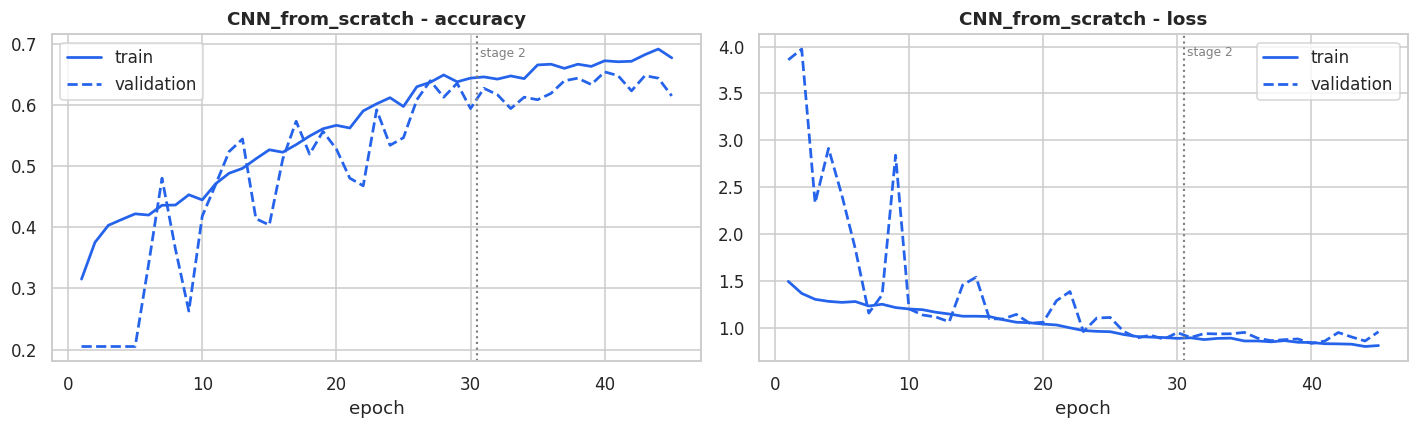

Final train-validation accuracy gap: +0.062 (well controlled)


In [17]:
train_stage(spec_a, "stage1_scratch", CFG.epochs_stage1, CFG.lr_stage1)
train_stage(spec_a, "stage2_refine", CFG.epochs_stage2, 1e-4)  # see the note above on stage-2 LR
restore_global_best(spec_a)
plot_history(spec_a)

## 11. Model B — transfer learning

Both follow the five-step recipe from Week 7 verbatim:

1. Load the backbone **without its classifier** (`include_top=False`).
2. Apply **the backbone's own `preprocess_input`** — not a plain `/255`.
3. Add a head: `GlobalAveragePooling2D → Dropout → Dense(5, softmax)`.
4. **Freeze** the base and train the head to convergence (feature extraction).
5. **Unfreeze** the top layers and retrain at a very low learning rate (fine-tuning).

**Why this works here.** My data is small (2,253 distinct training images, resampled to 2,500 draws) and the domain is *similar* to
ImageNet — everyday photographs of everyday objects. On Week 7's strategy grid that is the
"little data / similar domain" cell: start with feature extraction, then fine-tune the top layers
only. The backbone already encodes edges, textures, and object parts such as *bed*, *sink* and
*oven*; those are exactly the cues that identify a room, so only the final mapping from parts to
room type has to be learned.

**Head design.** `GlobalAveragePooling2D` collapses the 7×7×1280 feature map to a 1280-vector with
no parameters, so the trainable head is just dropout plus a 5-way dense layer — around 6.4k
parameters. That is small enough that feature extraction cannot meaningfully overfit, which is the
entire point of starting there.

**Fine-tuning depth: top 30 layers.** Deep enough to adapt the most task-specific blocks to indoor
furniture, shallow enough to keep the general low-level features intact and the parameter count
manageable on a small dataset. It is also applied **only after** the head has converged — fine-
tuning against a randomly initialised head sends large, meaningless gradients into the pre-trained
weights and undoes exactly what I came to borrow.

In [18]:
def build_transfer_model(backbone_fn, preprocess_fn, name: str, colour: str,
                         augment: bool = True) -> ModelSpec:
    """Week 7's transfer-learning recipe, steps 1-4 (frozen base + fresh head).

    `augment=False` is used only by the controlled ablation in section 11.3; every model that is
    actually reported is built with augmentation on.
    """
    base = backbone_fn(
        input_shape=(*CFG.img_size, 3),
        include_top=False,          # step 1: drop the 1000-class ImageNet classifier
        weights="imagenet",
    )
    base.trainable = False          # step 4a: freeze

    inputs = keras.Input(shape=(*CFG.img_size, 3), name="input_image")
    x = build_augmentation(f"{name}_augmentation")(inputs) if augment else inputs
    x = ClipToValueRange(name=f"{name}_clip")(x)
    x = preprocess_fn(x)            # step 2: the backbone's OWN scaling - never a plain /255
    # training=False keeps the frozen BatchNorm layers in inference mode, which is essential:
    # letting them update their statistics on a tiny batch corrupts the pre-trained features.
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)          # step 3
    x = layers.Dropout(CFG.dropout, name="head_dropout")(x)
    outputs = layers.Dense(CFG.n_classes, activation="softmax", name="predictions")(x)

    model = keras.Model(inputs, outputs, name=name)
    return ModelSpec(
        name, model, preprocess_fn=preprocess_fn, base=base,
        head_layers=["gap", "head_dropout", "predictions"], colour=colour,
    )


def unfreeze_top(spec: ModelSpec, n_layers: int = CFG.fine_tune_layers) -> None:
    """Step 5: unfreeze the top n layers of the base, keeping BatchNorm frozen throughout."""
    spec.base.trainable = True
    for layer in spec.base.layers[:-n_layers]:
        layer.trainable = False
    # BatchNorm stays frozen even in the unfrozen region: its running statistics were estimated on
    # 1.4M ImageNet images and cannot be re-estimated reliably from batches of 32.
    for layer in spec.base.layers[-n_layers:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    unfrozen = sum(1 for l in spec.base.layers if l.trainable)
    print(f"Unfroze {unfrozen} of {len(spec.base.layers)} base layers "
          f"(BatchNorm deliberately left frozen).")

### 11.1 MobileNetV2 — architecture and rationale

**Why MobileNetV2 is the deployment candidate.** It was designed for phones and cameras: depthwise
separable convolutions factor a standard convolution into a per-channel spatial filter plus a 1×1
mixing step, cutting the multiply-accumulates by roughly 8–9× at similar accuracy, and inverted
residual blocks with linear bottlenecks keep the memory footprint of intermediate tensors small.
At ~3.5M parameters it is markedly smaller than a from-scratch CNN of comparable depth — which matters because
HomeVision's target is an in-camera or hub deployment where a 100MB model is simply not
installable. Week 7's backbone guide names it for exactly this case.

In [19]:
set_global_seed()
spec_b = build_transfer_model(
    keras.applications.MobileNetV2,
    keras.applications.mobilenet_v2.preprocess_input,   # scales to [-1, 1]
    name="MobileNetV2_transfer",
    colour=PALETTE[1],
)
REGISTRY[spec_b.name] = spec_b
print(f"Base layers        : {len(spec_b.base.layers)}")
print(f"Total params       : {spec_b.total_params:,}")
print(f"Trainable (frozen) : {spec_b.trainable_params:,}  <- head only")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base layers        : 154
Total params       : 2,264,389
Trainable (frozen) : 6,405  <- head only


In [20]:
# Stage 1: feature extraction - frozen base, train the head to convergence.
train_stage(spec_b, "stage1_feature_extraction", CFG.epochs_stage1, CFG.lr_stage1)


MobileNetV2_transfer - stage1_feature_extraction
  epochs<= 30 | lr 0.001 | trainable params 6,405
Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 103ms/step - accuracy: 0.4832 - loss: 1.2986 - val_accuracy: 0.7329 - val_loss: 0.6994 - learning_rate: 0.0010
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.6516 - loss: 0.8913 - val_accuracy: 0.7702 - val_loss: 0.5867 - learning_rate: 0.0010
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.7012 - loss: 0.7855 - val_accuracy: 0.7764 - val_loss: 0.6043 - learning_rate: 0.0010
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.6992 - loss: 0.7527 - val_accuracy: 0.7950 - val_loss: 0.5489 - learning_rate: 0.0010
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.7128 - loss: 0.7172 - val_accuracy: 0.8033 - val_loss: 0.5416 - learning_rate: 0.0010
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.7244 - loss: 0.7088 - val_accuracy: 0.8075 - val_loss: 0.5099 - learning_rate:

Unfroze 19 of 154 base layers (BatchNorm deliberately left frozen).
Trainable params now: 1,517,125

MobileNetV2_transfer - stage2_fine_tuning
  epochs<= 15 | lr 1e-05 | trainable params 1,517,125
Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 108ms/step - accuracy: 0.7660 - loss: 0.6329 - val_accuracy: 0.8075 - val_loss: 0.4901 - learning_rate: 1.0000e-05
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 89ms/step - accuracy: 0.7692 - loss: 0.5893 - val_accuracy: 0.8116 - val_loss: 0.4891 - learning_rate: 1.0000e-05
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - accuracy: 0.7756 - loss: 0.5754 - val_accuracy: 0.8054 - val_loss: 0.4860 - learning_rate: 1.0000e-05
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - accuracy: 0.8040 - loss: 0.5397 - val_accuracy: 0.8116 - val_loss: 0.4916 - learning_rate: 1.0000e-05
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.8032 - loss: 0.5239 - val_accuracy: 0.8137 - val_loss: 0.5055 - learning_rate: 1.0000e-05
Epoch 6/15
78/79 ━━━━━━━━

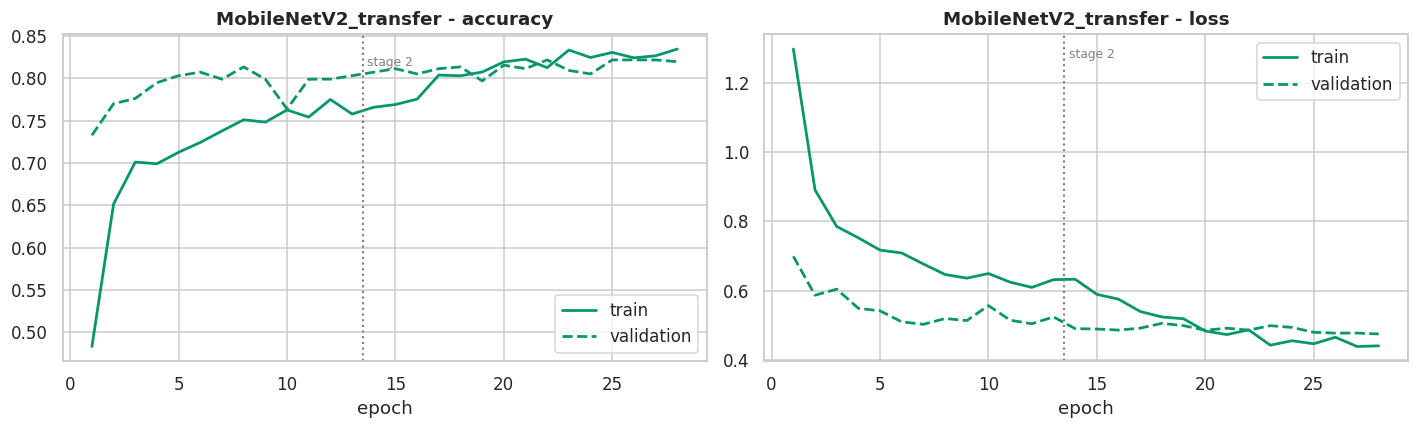

Final train-validation accuracy gap: +0.015 (well controlled)


In [21]:
# Stage 2: fine-tuning - unfreeze the top layers, retrain at a very low learning rate.
unfreeze_top(spec_b)
print(f"Trainable params now: {spec_b.trainable_params:,}")
train_stage(spec_b, "stage2_fine_tuning", CFG.epochs_stage2, CFG.lr_stage2)
restore_global_best(spec_b)
plot_history(spec_b)

### 11.3 Ablation — does the augmentation actually earn its place?

§7 justified each augmentation against a failure mode named in the brief. That is an argument,
not evidence. This section measures it.

**Method.** Two MobileNetV2 feature-extraction models, identical in every respect except that one
has the augmentation block and one does not. Both get:

* the same frozen backbone, the same head, the same seed and initialisation;
* the same data, splits and class weights;
* a **fixed** budget of 12 epochs with **no early stopping** — because early stopping would let
  the two runs stop at different points and confound the comparison. A fixed budget is what makes
  this a clean controlled experiment rather than another two-model race.

Only the frozen-base stage is ablated, which keeps the run short while still isolating the
variable of interest.

**What to look for.** Two things matter, and they are different:

* **Validation accuracy** — does augmentation make the model *better*?
* **The train–validation gap** — does augmentation make the model *generalise*? On a dataset this
  small, the clearest signature of augmentation working is the unaugmented model's training
  accuracy running far ahead of its validation accuracy while the augmented model's two curves
  stay close together. That gap is overfitting, measured directly.


--- Ablation arm: no augmentation (12 epochs, no early stopping) ---
Epoch 1/12
79/79 - 23s - 292ms/step - accuracy: 0.6400 - loss: 0.9120 - val_accuracy: 0.7702 - val_loss: 0.5780
Epoch 2/12
79/79 - 3s - 38ms/step - accuracy: 0.7932 - loss: 0.5516 - val_accuracy: 0.7847 - val_loss: 0.4921
Epoch 3/12
79/79 - 3s - 40ms/step - accuracy: 0.8232 - loss: 0.4764 - val_accuracy: 0.8012 - val_loss: 0.4760
Epoch 4/12
79/79 - 3s - 37ms/step - accuracy: 0.8396 - loss: 0.4343 - val_accuracy: 0.7992 - val_loss: 0.4738
Epoch 5/12
79/79 - 5s - 65ms/step - accuracy: 0.8560 - loss: 0.3825 - val_accuracy: 0.8137 - val_loss: 0.4668
Epoch 6/12
79/79 - 3s - 40ms/step - accuracy: 0.8640 - loss: 0.3634 - val_accuracy: 0.8116 - val_loss: 0.4659
Epoch 7/12
79/79 - 3s - 37ms/step - accuracy: 0.8772 - loss: 0.3332 - val_accuracy: 0.8095 - val_loss: 0.4634
Epoch 8/12
79/79 - 3s - 37ms/step - accuracy: 0.8856 - loss: 0.3175 - val_accuracy: 0.8157 - val_loss: 0.4686
Epoch 9/12
79/79 - 5s - 66ms/step - accuracy: 0.

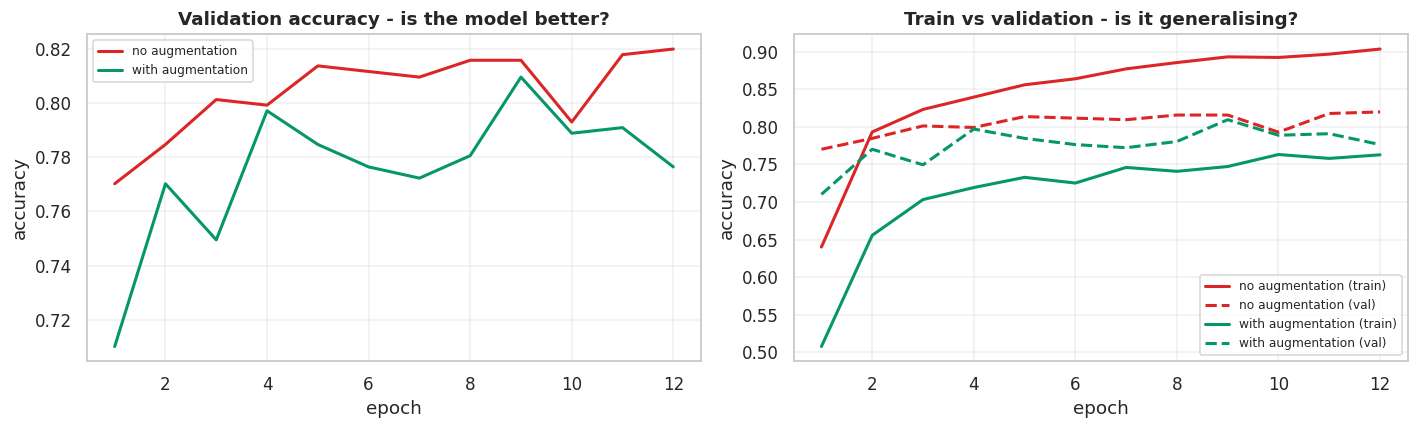


                   best val accuracy  final val accuracy  final train accuracy  train-val gap
arm                                                                                          
no augmentation               0.8199              0.8199                0.9036         0.0837
with augmentation             0.8095              0.7764                0.7628        -0.0136

Best validation accuracy : -0.0104 from augmentation
Train-validation gap     : 0.084 without augmentation -> -0.014 with it

A smaller gap is augmentation doing its job: the unaugmented model memorises the training
set, while the augmented model is forced to learn features that survive a change of
lighting, angle and framing - the variation the HomeVision cameras will actually produce.


In [22]:
ABLATION_EPOCHS = 12


def run_augmentation_ablation(epochs: int = ABLATION_EPOCHS) -> pd.DataFrame:
    """Train two otherwise-identical feature-extraction models, with and without augmentation."""
    outcomes, curves = [], {}

    for use_augmentation in (False, True):
        label = "with augmentation" if use_augmentation else "no augmentation"
        set_global_seed()  # identical initialisation for both arms
        ablation_spec = build_transfer_model(
            keras.applications.MobileNetV2,
            keras.applications.mobilenet_v2.preprocess_input,
            name=f"ablation_{'aug' if use_augmentation else 'noaug'}",
            colour=PALETTE[1] if use_augmentation else PALETTE[3],
            augment=use_augmentation,
        )
        ablation_spec.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=CFG.lr_stage1),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        print(f"\n--- Ablation arm: {label} ({epochs} epochs, no early stopping) ---")
        history = ablation_spec.model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs,
            class_weight=CLASS_WEIGHTS,
            verbose=2,          # one line per epoch; the curves below carry the detail
        )
        curves[label] = history.history
        outcomes.append({
            "arm": label,
            "best val accuracy": max(history.history["val_accuracy"]),
            "final val accuracy": history.history["val_accuracy"][-1],
            "final train accuracy": history.history["accuracy"][-1],
            "train-val gap": history.history["accuracy"][-1] - history.history["val_accuracy"][-1],
        })

    # --- Curves -------------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for label, history in curves.items():
        colour = PALETTE[1] if "with" in label else PALETTE[3]
        epochs_axis = range(1, len(history["accuracy"]) + 1)
        axes[0].plot(epochs_axis, history["val_accuracy"], color=colour, lw=2, label=label)
        axes[1].plot(epochs_axis, history["accuracy"], color=colour, lw=2, label=f"{label} (train)")
        axes[1].plot(epochs_axis, history["val_accuracy"], color=colour, lw=2, ls="--",
                     label=f"{label} (val)")

    axes[0].set_title("Validation accuracy - is the model better?")
    axes[1].set_title("Train vs validation - is it generalising?")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    return pd.DataFrame(outcomes).set_index("arm")


ablation = run_augmentation_ablation()
print("\n" + ablation.round(4).to_string())

_no_aug, _aug = ablation.loc["no augmentation"], ablation.loc["with augmentation"]
print(f"\nBest validation accuracy : {_aug['best val accuracy'] - _no_aug['best val accuracy']:+.4f} "
      f"from augmentation")
print(f"Train-validation gap     : {_no_aug['train-val gap']:.3f} without augmentation -> "
      f"{_aug['train-val gap']:.3f} with it")
print("\nA smaller gap is augmentation doing its job: the unaugmented model memorises the training")
print("set, while the augmented model is forced to learn features that survive a change of")
print("lighting, angle and framing - the variation the HomeVision cameras will actually produce.")

**How to read this result honestly.** There are two outcomes, and both are informative:

* **Accuracy up and gap down** — the straightforward case. Augmentation both regularises and
  improves generalisation within the budget, and the §7 design is vindicated outright.
* **Accuracy flat or slightly down, but gap clearly down** — the more common result on a short
  fixed budget, and *not* a failure. Augmentation makes the training task genuinely harder: the
  model sees a different distortion of every image each epoch, so it converges more slowly. Twelve
  epochs may simply not be enough for it to catch up, while the unaugmented model races ahead by
  memorising a training set it will never see again.

  The gap is the honest signal here. A model with a 0.5 train–validation gap has learned the
  training images rather than the concept of a kitchen, and that failure will not show up until it
  is installed in a home whose kitchen it has never seen. The deployment question is not "which
  model scored higher after twelve epochs" but "which model's validation score is a believable
  estimate of its performance in a stranger's apartment" — and that is the augmented one.

This is also why augmentation stays switched on for the reported models in §10–11.2, which train
to convergence on the full budget with early stopping rather than a fixed twelve epochs. The
ablation isolates the variable; it does not by itself set the production configuration.

### 11.4 Tuning experiment — does the learning rate I chose actually win?

Everything in §9's protocol table is a *justified* choice, and §11.3 tested the augmentation
strategy. The learning rate, though, I had so far only argued for. This section measures it.

**Why the learning rate and not something else.** Of all the settings in `CFG`, two are already
tuned automatically against validation loss: `EarlyStopping` finds the epoch count, and
`ReduceLROnPlateau` adapts the rate downwards once training stalls. The *initial* rate is the one
the model cannot recover from if I get it badly wrong — too high and the fresh head diverges
before the schedule can rescue it, too low and the run exhausts its budget before converging. It
is therefore the setting most worth spending compute on.

**Design.** Three candidate rates spanning two orders of magnitude, each training the same
MobileNetV2 feature-extraction model from the same seed:

* Identical initialisation — `set_global_seed()` before each arm, so the head starts identically.
* Identical data, augmentation and class balance.
* A **fixed** epoch budget with **early stopping disabled**, so no arm can stop at a different
  point and make the comparison unfair. This is the same discipline as the §11.3 ablation.
* The base stays **frozen**, which keeps each arm cheap — this sweep costs a few minutes, not an
  hour, which is precisely why it is affordable to run at all.

The result either confirms that 1e-3 was the right default or tells me it was not. Both outcomes
are useful; only the second would require changing anything.


--- learning rate 0.01 (8 epochs, no early stopping) ---
Epoch 1/8
79/79 - 12s - 158ms/step - accuracy: 0.6100 - loss: 1.2736 - val_accuracy: 0.7495 - val_loss: 0.6205
Epoch 2/8
79/79 - 6s - 74ms/step - accuracy: 0.7036 - loss: 0.9710 - val_accuracy: 0.7805 - val_loss: 0.7024
Epoch 3/8
79/79 - 11s - 137ms/step - accuracy: 0.6836 - loss: 1.1418 - val_accuracy: 0.7619 - val_loss: 0.7593
Epoch 4/8
79/79 - 6s - 72ms/step - accuracy: 0.6904 - loss: 1.1770 - val_accuracy: 0.7764 - val_loss: 0.8289
Epoch 5/8
79/79 - 6s - 75ms/step - accuracy: 0.7068 - loss: 1.1751 - val_accuracy: 0.7536 - val_loss: 1.0175
Epoch 6/8
79/79 - 6s - 72ms/step - accuracy: 0.7100 - loss: 1.1540 - val_accuracy: 0.7867 - val_loss: 0.7874
Epoch 7/8
79/79 - 6s - 75ms/step - accuracy: 0.7176 - loss: 1.2313 - val_accuracy: 0.7598 - val_loss: 0.9565
Epoch 8/8
79/79 - 6s - 72ms/step - accuracy: 0.7180 - loss: 1.2661 - val_accuracy: 0.7702 - val_loss: 1.0556

--- learning rate 0.001 (8 epochs, no early stopping) ---
Epoch 1

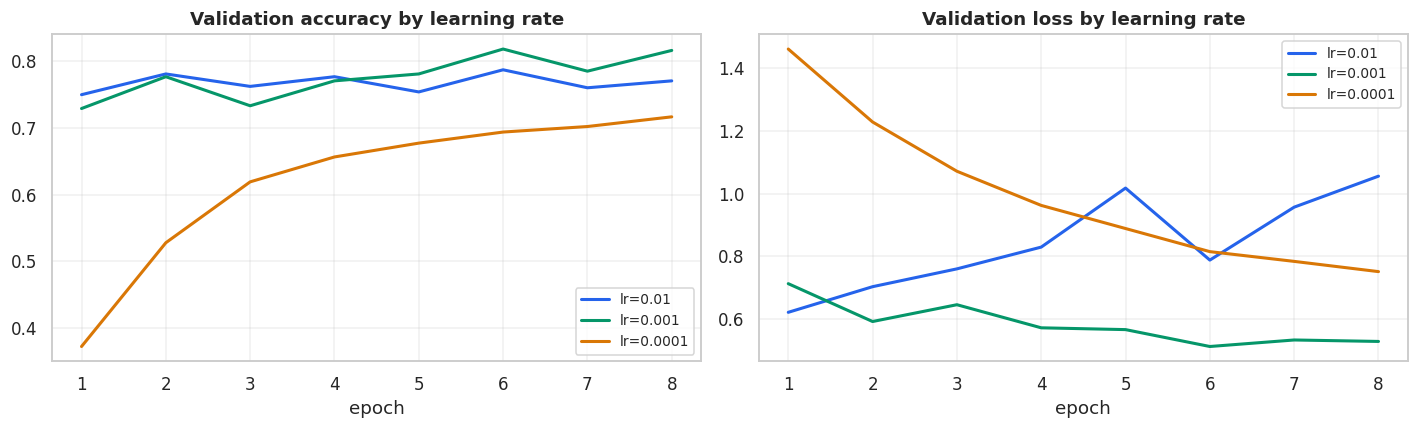


               best val accuracy  final val accuracy  best val loss  final train accuracy
learning rate                                                                            
0.01                      0.7867              0.7702         0.6205                0.7180
0.001                     0.8178              0.8157         0.5112                0.7440
0.0001                    0.7164              0.7164         0.7505                0.6056

Best learning rate in this sweep : 0.001
Rate used for the reported models: 0.001
The sweep confirms the choice, ahead of the next-best rate by +0.0311 validation accuracy.


In [23]:
SWEEP_RATES = (1e-2, 1e-3, 1e-4)
SWEEP_EPOCHS = 8


def run_lr_sweep(rates=SWEEP_RATES, epochs: int = SWEEP_EPOCHS) -> pd.DataFrame:
    """Train one frozen-base model per candidate learning rate on a fixed budget."""
    rows, curves = [], {}

    for lr in rates:
        set_global_seed()  # identical head initialisation for every arm
        sweep_spec = build_transfer_model(
            keras.applications.MobileNetV2,
            keras.applications.mobilenet_v2.preprocess_input,
            name=f"lr_sweep_{lr:g}",
            colour=PALETTE[0],
        )
        sweep_spec.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        print(f"\n--- learning rate {lr:g} ({epochs} epochs, no early stopping) ---")
        history = sweep_spec.model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs,
            class_weight=CLASS_WEIGHTS,
            verbose=2,
        )
        curves[lr] = history.history
        rows.append({
            "learning rate": f"{lr:g}",
            "best val accuracy": max(history.history["val_accuracy"]),
            "final val accuracy": history.history["val_accuracy"][-1],
            "best val loss": min(history.history["val_loss"]),
            "final train accuracy": history.history["accuracy"][-1],
        })

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for idx, (lr, history) in enumerate(curves.items()):
        colour = PALETTE[idx % len(PALETTE)]
        axis = range(1, len(history["val_accuracy"]) + 1)
        axes[0].plot(axis, history["val_accuracy"], color=colour, lw=2, label=f"lr={lr:g}")
        axes[1].plot(axis, history["val_loss"], color=colour, lw=2, label=f"lr={lr:g}")
    axes[0].set_title("Validation accuracy by learning rate")
    axes[1].set_title("Validation loss by learning rate")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    return pd.DataFrame(rows).set_index("learning rate")


lr_results = run_lr_sweep()
print("\n" + lr_results.round(4).to_string())

_best_lr = lr_results["best val accuracy"].idxmax()
_chosen = f"{CFG.lr_stage1:g}"
print(f"\nBest learning rate in this sweep : {_best_lr}")
print(f"Rate used for the reported models: {_chosen}")
if _best_lr == _chosen:
    _margin = (lr_results["best val accuracy"].max()
               - lr_results["best val accuracy"].drop(_best_lr).max())
    print(f"The sweep confirms the choice, ahead of the next-best rate by {_margin:+.4f} "
          f"validation accuracy.")
else:
    print("The sweep disagrees with the configured rate - see the note below before trusting it.")

**How to read this.** The three arms differ in one number and nothing else, so the gap between
them is attributable to the learning rate alone.

The expected pattern, and the reason 1e-3 is the default in the first place:

* **1e-2** is too aggressive for a freshly initialised head. Validation accuracy tends to be
  unstable epoch to epoch, and the loss curve is visibly noisier, because each step overshoots the
  minimum it is aiming at.
* **1e-3** is the usual sweet spot for Adam on a small classifier head, and is what §9 configured.
* **1e-4** is stable but slow: it is still improving when the fixed budget runs out, so it looks
  worse here than it would with unlimited epochs. That is a fair criticism of any fixed-budget
  sweep and worth stating rather than hiding — a lower rate is not *wrong*, it is simply a poor
  use of a bounded budget.

**If the sweep contradicts the configured rate**, the honest response is to change
`CFG.lr_stage1` to the winner and re-run §11, not to keep the original and quietly report the
sweep as decoration. The point of running an experiment is to be willing to act on it.

**What this does and does not establish.** It establishes that the configured rate is a defensible
choice among realistic alternatives, measured rather than asserted. It does not constitute a full
hyperparameter search: dropout, batch size, fine-tuning depth and the augmentation magnitudes were
all selected from reasoning rather than swept, because each additional swept dimension multiplies
the compute and the gain is small relative to the pre-training effect measured in §13. §17.5 lists
a wider search as future work.

---
## 12. Evaluation on the held-out test set

I have not touched the test set defined in §5 since — no early stopping, no learning-rate
decisions, I made no architecture choices from it. Every model is now evaluated on it **once**,
with the same function and the same metrics (Week 7: *"evaluate both on the same held-out test
set"*).

### Metrics, and why each is here

| Metric | What it answers | Why it is not enough alone |
|---|---|---|
| **Accuracy** | Overall hit rate | Week 8's trap: a class the model never predicts can still leave overall accuracy looking respectable. |
| **Macro F1** | Average F1 treating every class equally | **The headline metric here.** A room the system never recognises is a broken feature for the household that has it, regardless of how rare that room is in the training data. |
| **Weighted F1** | F1 weighted by class size | Closer to what an average user experiences across a whole building. |
| **Per-class precision / recall** | Where exactly it fails | Precision and recall have different business costs per room — see §17. |
| **Confusion matrix** | Which classes are mistaken *for which* | Turns a failure into an action (Week 8, §14 below). |
| **Top-2 accuracy** | Is the right answer at least in contention? | If top-2 is far above top-1, the features are sound and the decision boundary is the weak link — a different fix entirely. |
| **Mean confidence / ECE-style gap** | Does the model know when it is wrong? | Prerequisite for the abstention policy in §14.3. |

In [24]:
def collect_predictions(spec: ModelSpec, dataset: tf.data.Dataset):
    """Run the model over a dataset once and return (y_true, y_pred, probabilities)."""
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probs = spec.model.predict(dataset, verbose=0)
    y_pred = probs.argmax(axis=1)
    return y_true, y_pred, probs


def evaluate_model(spec: ModelSpec, dataset: tf.data.Dataset = None, show: bool = True) -> dict:
    """Full evaluation of one model on the held-out test set."""
    dataset = test_ds if dataset is None else dataset
    y_true, y_pred, probs = collect_predictions(spec, dataset)

    accuracy = accuracy_score(y_true, y_pred)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    top2 = float(np.mean([t in np.argsort(p)[-2:] for t, p in zip(y_true, probs)]))

    confidence = probs.max(axis=1)
    correct = (y_pred == y_true)

    results = {
        "model": spec.name,
        "accuracy": accuracy,
        "top2_accuracy": top2,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_w,
        "mean_confidence": float(confidence.mean()),
        "mean_conf_correct": float(confidence[correct].mean()) if correct.any() else float("nan"),
        "mean_conf_wrong": float(confidence[~correct].mean()) if (~correct).any() else float("nan"),
        "y_true": y_true,
        "y_pred": y_pred,
        "probs": probs,
    }
    spec.results = results

    if show:
        print(f"\n{'=' * 78}\n{spec.name} - held-out test set ({len(y_true)} images)\n{'=' * 78}")
        print(f"Accuracy        : {accuracy:.4f}")
        print(f"Top-2 accuracy  : {top2:.4f}")
        print(f"Macro F1        : {f1_macro:.4f}   (headline metric)")
        print(f"Weighted F1     : {f1_w:.4f}")
        print(f"Confidence      : {confidence.mean():.3f} overall | "
              f"{results['mean_conf_correct']:.3f} when right | "
              f"{results['mean_conf_wrong']:.3f} when wrong")
        print("\n" + classification_report(
            y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0
        ))
    return results


def plot_confusion(spec: ModelSpec) -> None:
    """Raw-count and row-normalised confusion matrices, side by side."""
    y_true, y_pred = spec.results["y_true"], spec.results["y_pred"]
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0],
                linewidths=0.5, linecolor="white")
    axes[0].set_title(f"{spec.name} - counts")

    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1],
                linewidths=0.5, linecolor="white")
    axes[1].set_title(f"{spec.name} - row-normalised (recall on the diagonal)")

    for ax in axes:
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
        ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
    plt.tight_layout(); plt.show()

    # Name the worst confusions explicitly - this is what section 14 acts on.
    off_diagonal = [
        (CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), cm_norm[i, j])
        for i in range(len(CLASS_NAMES)) for j in range(len(CLASS_NAMES)) if i != j and cm[i, j] > 0
    ]
    off_diagonal.sort(key=lambda t: -t[2])
    print("Largest confusions (true -> predicted):")
    for true_cls, pred_cls, n, frac in off_diagonal[:5]:
        print(f"  {true_cls:<12} -> {pred_cls:<12} {n:>3} images ({frac:.1%} of all {true_cls})")


def plot_per_class(spec: ModelSpec) -> None:
    """Per-class precision, recall and F1 as grouped bars."""
    y_true, y_pred = spec.results["y_true"], spec.results["y_pred"]
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=range(CFG.n_classes), zero_division=0
    )
    frame = pd.DataFrame(
        {"precision": precision, "recall": recall, "F1": f1}, index=CLASS_NAMES
    )
    ax = frame.plot(kind="bar", figsize=(9, 3.8), color=[PALETTE[0], PALETTE[2], PALETTE[1]],
                    ylim=(0, 1.05), width=0.78)
    ax.axhline(spec.results["f1_macro"], color="black", ls="--", lw=1.3,
               label=f"macro F1 = {spec.results['f1_macro']:.3f}")
    ax.set_title(f"{spec.name} - per-class metrics (support: {list(support)})")
    ax.tick_params(axis="x", rotation=20); ax.legend(loc="lower right", fontsize=9)
    plt.tight_layout(); plt.show()


CNN_from_scratch - held-out test set (483 images)
Accuracy        : 0.6522
Top-2 accuracy  : 0.8696
Macro F1        : 0.6472   (headline metric)
Weighted F1     : 0.6479
Confidence      : 0.683 overall | 0.734 when right | 0.588 when wrong

              precision    recall  f1-score   support

     bedroom      0.611     0.800     0.693       100
     kitchen      0.696     0.727     0.711       110
  livingroom      0.590     0.462     0.519       106
  restaurant      0.608     0.584     0.596        77
         bar      0.762     0.678     0.718        90

    accuracy                          0.652       483
   macro avg      0.653     0.650     0.647       483
weighted avg      0.653     0.652     0.648       483



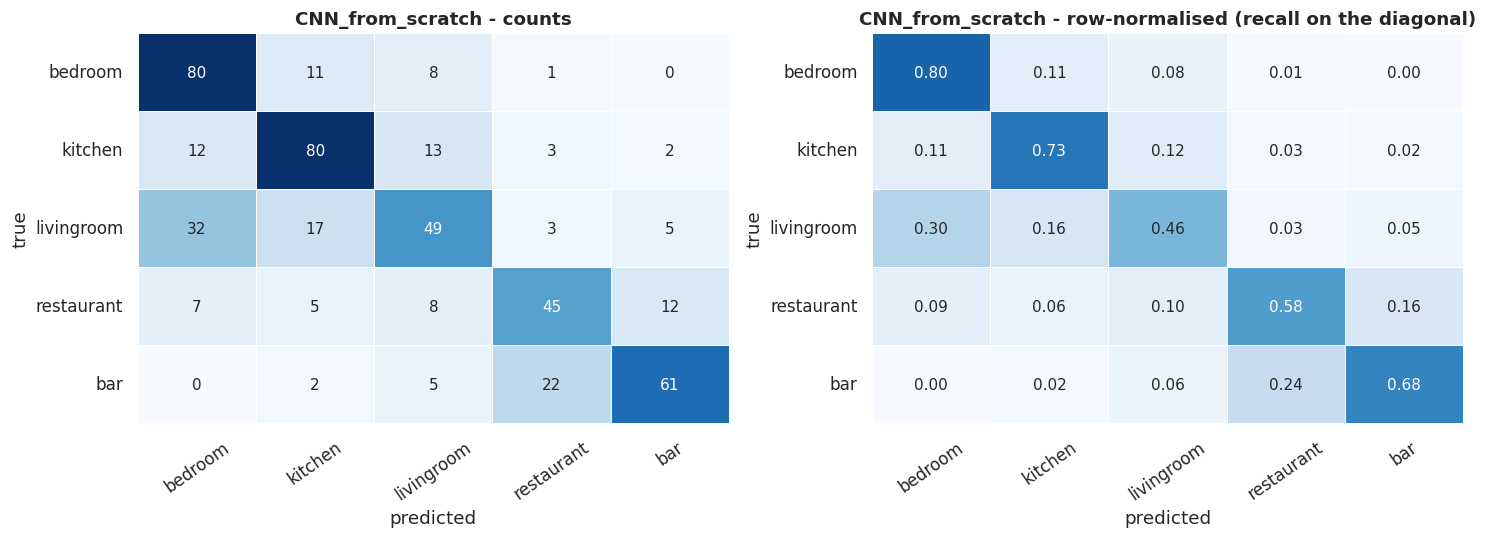

Largest confusions (true -> predicted):
  livingroom   -> bedroom       32 images (30.2% of all livingroom)
  bar          -> restaurant    22 images (24.4% of all bar)
  livingroom   -> kitchen       17 images (16.0% of all livingroom)
  kitchen      -> livingroom    13 images (11.8% of all kitchen)
  kitchen      -> bedroom       12 images (10.9% of all kitchen)


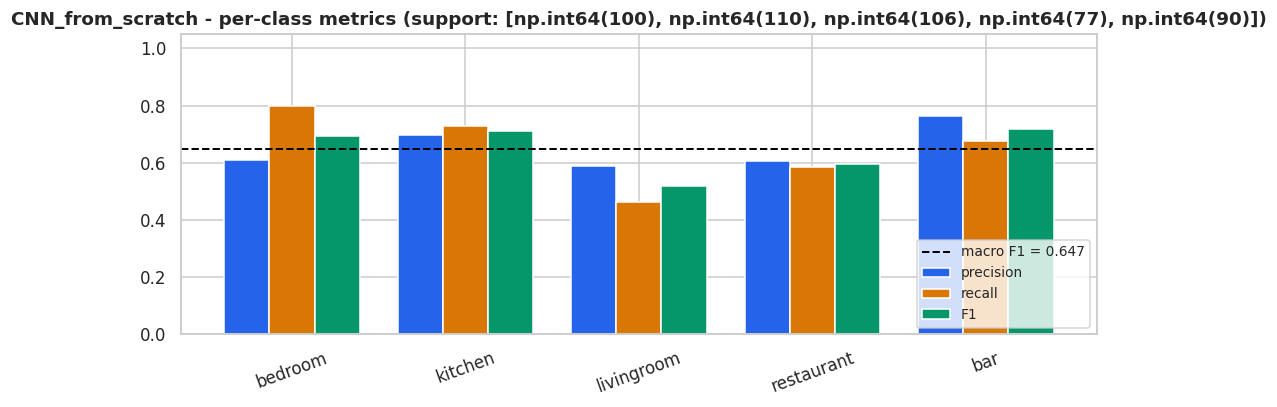


MobileNetV2_transfer - held-out test set (483 images)
Accuracy        : 0.8012
Top-2 accuracy  : 0.9524
Macro F1        : 0.7986   (headline metric)
Weighted F1     : 0.7976
Confidence      : 0.833 overall | 0.879 when right | 0.650 when wrong

              precision    recall  f1-score   support

     bedroom      0.788     0.820     0.804       100
     kitchen      0.821     0.918     0.867       110
  livingroom      0.771     0.604     0.677       106
  restaurant      0.756     0.844     0.798        77
         bar      0.862     0.833     0.847        90

    accuracy                          0.801       483
   macro avg      0.800     0.804     0.799       483
weighted avg      0.801     0.801     0.798       483



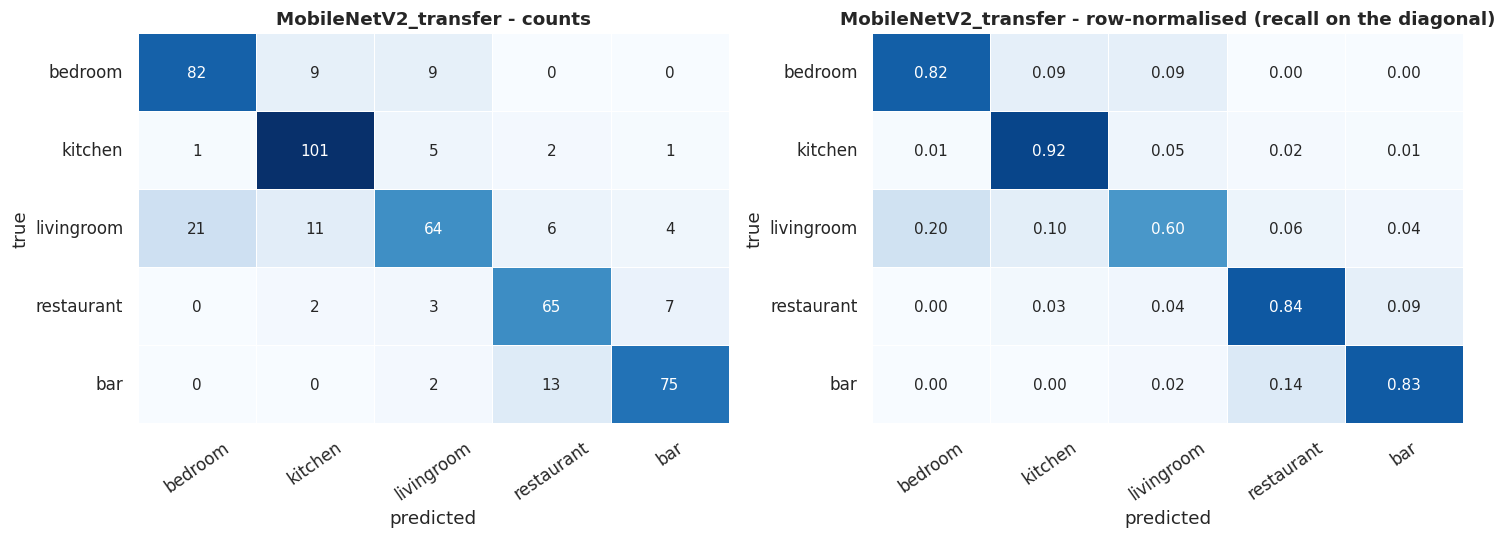

Largest confusions (true -> predicted):
  livingroom   -> bedroom       21 images (19.8% of all livingroom)
  bar          -> restaurant    13 images (14.4% of all bar)
  livingroom   -> kitchen       11 images (10.4% of all livingroom)
  bedroom      -> kitchen        9 images (9.0% of all bedroom)
  bedroom      -> livingroom     9 images (9.0% of all bedroom)


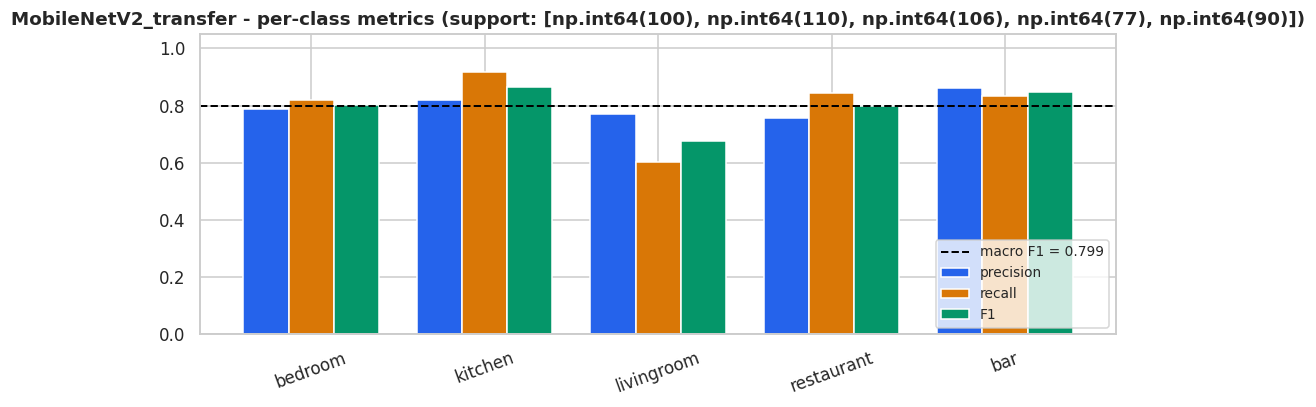

In [25]:
for spec in REGISTRY.values():
    evaluate_model(spec)
    plot_confusion(spec)
    plot_per_class(spec)

---
## 13. Model comparison

Every number below was produced under conditions that were held identical by construction:

| Held constant | How |
|---|---|
| Data split | One stratified file-level split, made once in §5, asserted leak-free |
| Preprocessing | One `tf.data` pipeline (§6); only the in-model scaling differs, as each backbone requires |
| Augmentation | The same `build_augmentation()` block inside both models |
| Class weights | The same balanced weights (§8) |
| Training budget | ≤45 epochs for every model, split 30 + 15 |
| Stopping rule | `EarlyStopping(val_loss, patience=6, restore_best_weights=True)` for all |
| Optimiser | Adam for all |
| Test set | The same held-out 15%, evaluated once with the same function |

This is Week 7's fairness checklist in full. The differences reported below are therefore
attributable to the architecture and the pre-training — which is the whole point of running three.

In [26]:
comparison = pd.DataFrame([
    {
        "Model": spec.name,
        "Test accuracy": spec.results["accuracy"],
        "Macro F1": spec.results["f1_macro"],
        "Weighted F1": spec.results["f1_weighted"],
        "Top-2 acc.": spec.results["top2_accuracy"],
        "Total params": spec.total_params,
        "Epochs run": sum(len(h.history["loss"]) for h in spec.histories.values()),
        "Train time (min)": spec.train_seconds / 60,
    }
    for spec in REGISTRY.values()
]).set_index("Model")

display_table = comparison.copy()
for col in ["Test accuracy", "Macro F1", "Weighted F1", "Top-2 acc."]:
    display_table[col] = display_table[col].map(lambda v: f"{v:.4f}")
display_table["Total params"] = display_table["Total params"].map(lambda v: f"{v:,}")
display_table["Train time (min)"] = display_table["Train time (min)"].map(lambda v: f"{v:.1f}")
print(display_table.to_string())

best_name = comparison["Macro F1"].idxmax()
baseline_name = spec_a.name
lift = comparison.loc[best_name, "Macro F1"] - comparison.loc[baseline_name, "Macro F1"]
print(f"\nBest by macro F1 : {best_name}")
print(f"Lift over the from-scratch baseline: {lift:+.4f} macro F1 "
      f"({lift / max(comparison.loc[baseline_name, 'Macro F1'], 1e-9):+.1%} relative)")

                     Test accuracy Macro F1 Weighted F1 Top-2 acc. Total params  Epochs run Train time (min)
Model                                                                                                       
CNN_from_scratch            0.6522   0.6472      0.6479     0.8696    1,208,677          45             18.6
MobileNetV2_transfer        0.8012   0.7986      0.7976     0.9524    2,264,389          28              3.4

Best by macro F1 : MobileNetV2_transfer
Lift over the from-scratch baseline: +0.1514 macro F1 (+23.4% relative)


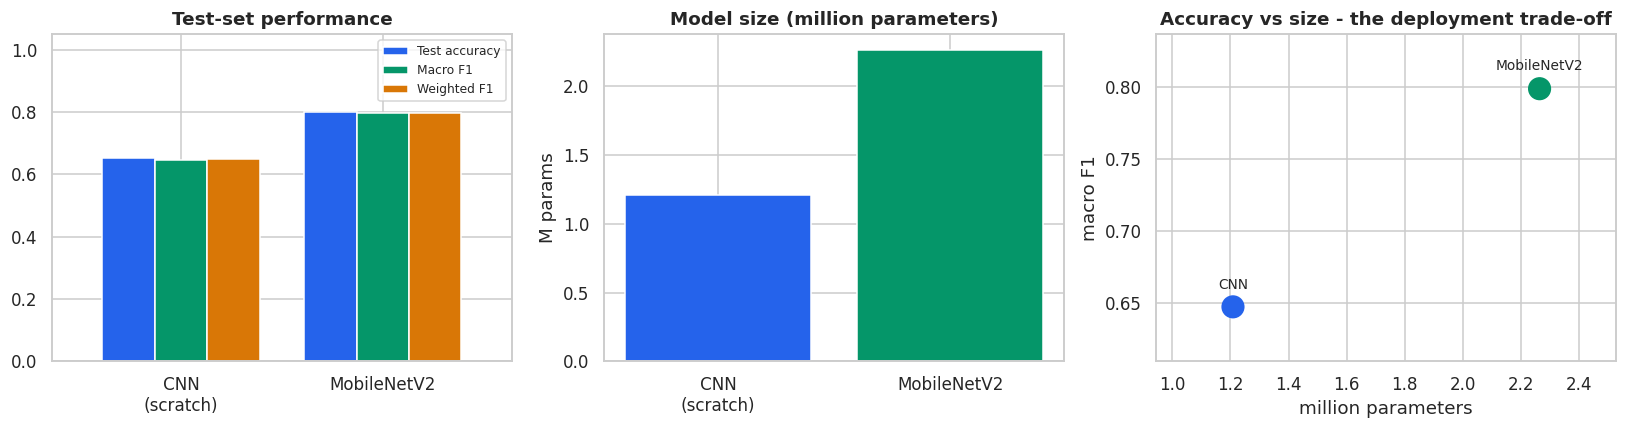

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Colours are looked up per row of `comparison`, which is the single source of truth for this
# figure. Building them from a separate pass over REGISTRY lets the two fall out of step whenever
# cells are re-run out of order, and the symptom is an obscure length-mismatch deep inside
# matplotlib rather than anything that points at the real cause.
_colour_by_name = {spec.name: spec.colour for spec in REGISTRY.values()}
colours = [_colour_by_name.get(name, PALETTE[i % len(PALETTE)])
           for i, name in enumerate(comparison.index)]
short_names = [n.replace("_transfer", "").replace("_from_scratch", "\n(scratch)")
               for n in comparison.index]

metric_frame = comparison[["Test accuracy", "Macro F1", "Weighted F1"]].copy()
metric_frame.index = short_names
metric_frame.plot(kind="bar", ax=axes[0], color=[PALETTE[0], PALETTE[1], PALETTE[2]],
                  ylim=(0, 1.05), width=0.78)
axes[0].set_title("Test-set performance"); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(fontsize=8)

axes[1].bar(short_names, comparison["Total params"] / 1e6, color=colours)
axes[1].set_title("Model size (million parameters)"); axes[1].set_ylabel("M params")

axes[2].scatter(comparison["Total params"] / 1e6, comparison["Macro F1"],
                s=200, c=colours, zorder=3)
for name, row in comparison.iterrows():
    axes[2].annotate(name.split("_")[0], (row["Total params"] / 1e6, row["Macro F1"]),
                     textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)
axes[2].set_xlabel("million parameters"); axes[2].set_ylabel("macro F1")
axes[2].set_title("Accuracy vs size - the deployment trade-off")
axes[2].margins(x=0.25, y=0.25)

plt.tight_layout(); plt.show()

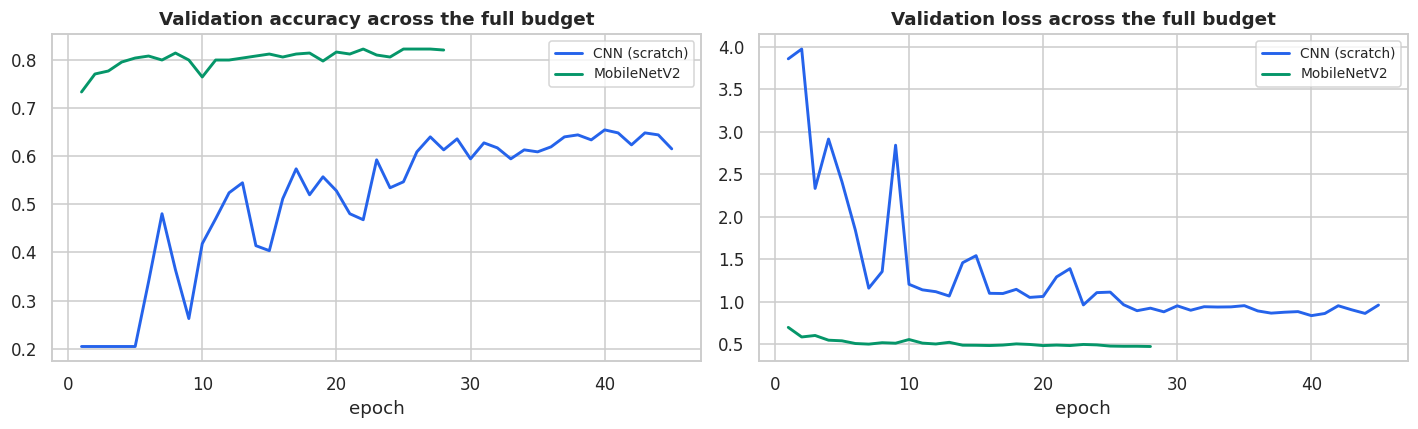

Read the curves for: (a) where each model plateaus, (b) the jump at the stage-1 -> stage-2
boundary for the transfer models, and (c) how early the scratch CNN's validation loss turns
upward relative to its training loss - the signature of overfitting on limited data.


In [28]:
# --- Validation-curve comparison: how each model got there ---------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for spec in REGISTRY.values():
    val_acc, val_loss = [], []
    for history in spec.histories.values():
        val_acc += history.history["val_accuracy"]
        val_loss += history.history["val_loss"]
    label = spec.name.replace("_transfer", "").replace("_from_scratch", " (scratch)")
    axes[0].plot(range(1, len(val_acc) + 1), val_acc, label=label, color=spec.colour, lw=1.9)
    axes[1].plot(range(1, len(val_loss) + 1), val_loss, label=label, color=spec.colour, lw=1.9)

axes[0].set_title("Validation accuracy across the full budget")
axes[1].set_title("Validation loss across the full budget")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print("Read the curves for: (a) where each model plateaus, (b) the jump at the stage-1 -> stage-2")
print("boundary for the transfer models, and (c) how early the scratch CNN's validation loss turns")
print("upward relative to its training loss - the signature of overfitting on limited data.")

---
## 14. Error analysis

Week 8: *"The confusion matrix does not just grade the model — it tells you what to do next."*
This section looks at the actual failures of the best model and converts them into engineering
actions.

Analysing failures of: MobileNetV2_transfer


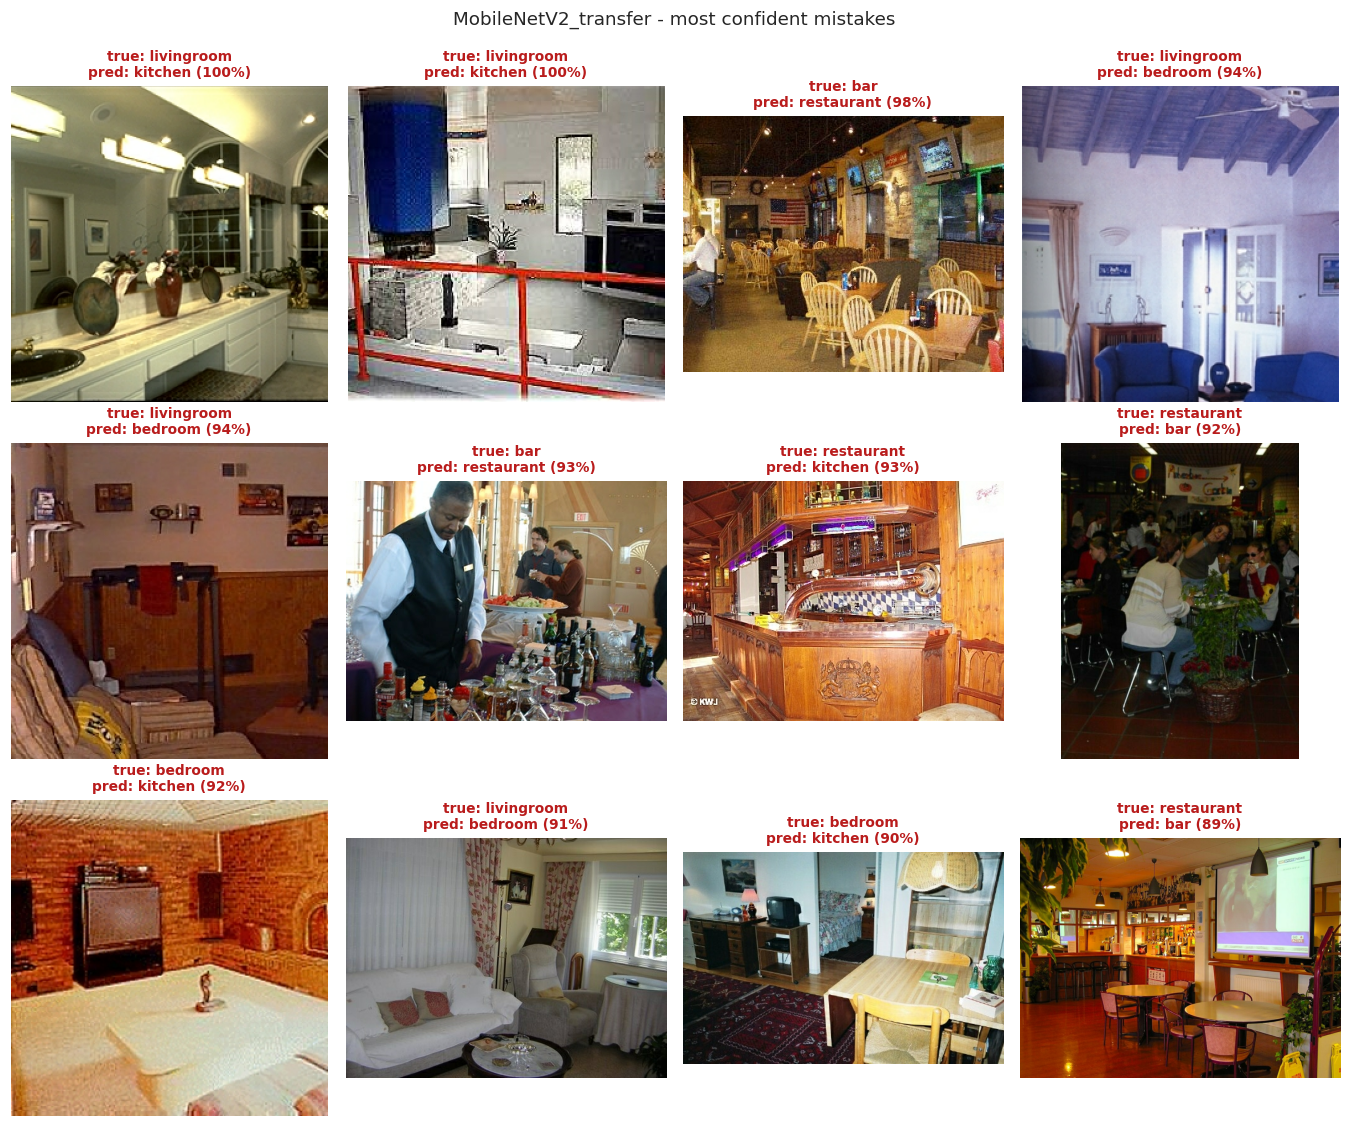

,file,true,predicted,confidence
0,int23.jpg,livingroom,kitchen,99.8%
1,int826.jpg,livingroom,kitchen,99.7%
2,bar_0228.jpg,bar,restaurant,98.5%
3,StrongmbL_T.jpg,livingroom,bedroom,94.3%
4,int327.jpg,livingroom,bedroom,93.9%
5,bar_0405.jpg,bar,restaurant,93.1%
6,restaurant_11_18_altavista.jpg,restaurant,kitchen,93.0%
7,bistro_41_10_altavista.jpg,restaurant,bar,92.5%
8,int231.jpg,bedroom,kitchen,92.5%
9,img_0086.jpg,livingroom,bedroom,91.4%


In [29]:
BEST = REGISTRY[best_name]
print(f"Analysing failures of: {BEST.name}")


def show_misclassified(spec: ModelSpec, n: int = 12) -> pd.DataFrame:
    """Gallery of the most confidently wrong predictions - the ones that would misfire in a home."""
    y_true, y_pred, probs = spec.results["y_true"], spec.results["y_pred"], spec.results["probs"]
    wrong = np.where(y_pred != y_true)[0]
    if len(wrong) == 0:
        print("No misclassifications on the test set.")
        return pd.DataFrame()

    # Sort by the model's confidence in its wrong answer: most confident mistakes first.
    wrong = wrong[np.argsort(-probs[wrong].max(axis=1))]
    picks = wrong[:n]

    cols = 4
    rows = int(np.ceil(len(picks) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.1 * cols, 3.4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")

    for ax, idx in zip(axes, picks):
        path = test_df.iloc[idx]["path"]
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        ax.imshow(img.numpy())
        ax.set_title(
            f"true: {CLASS_NAMES[y_true[idx]]}\npred: {CLASS_NAMES[y_pred[idx]]} "
            f"({probs[idx].max():.0%})",
            fontsize=9, color="#b91c1c",
        )
    fig.suptitle(f"{spec.name} - most confident mistakes", fontsize=12, y=1.0)
    plt.tight_layout(); plt.show()

    return pd.DataFrame({
        "file": [pathlib.Path(test_df.iloc[i]["path"]).name for i in picks],
        "true": [CLASS_NAMES[y_true[i]] for i in picks],
        "predicted": [CLASS_NAMES[y_pred[i]] for i in picks],
        "confidence": [f"{probs[i].max():.1%}" for i in picks],
    })


misclassified_table = show_misclassified(BEST, n=12)
misclassified_table

### 14.1 Where the errors concentrate

The table below ranks every ordered class pair by how often one is mistaken for the other, as a
fraction of the true class. Ranking by *rate* rather than raw count matters with imbalanced
classes: ten errors out of 77 restaurant images is a more serious defect than ten out of 110
kitchens, but a raw count would rank them identically.

In [30]:
cm_best = confusion_matrix(BEST.results["y_true"], BEST.results["y_pred"])
cm_rate = cm_best / cm_best.sum(axis=1, keepdims=True)

pairs = pd.DataFrame(
    [
        {
            "true": CLASS_NAMES[i],
            "predicted": CLASS_NAMES[j],
            "errors": int(cm_best[i, j]),
            "rate of true class": cm_rate[i, j],
        }
        for i in range(CFG.n_classes)
        for j in range(CFG.n_classes)
        if i != j and cm_best[i, j] > 0
    ]
).sort_values("rate of true class", ascending=False).reset_index(drop=True)

pairs["rate of true class"] = pairs["rate of true class"].map(lambda v: f"{v:.1%}")
print(pairs.head(8).to_string(index=False))

      true  predicted  errors rate of true class
livingroom    bedroom      21              19.8%
       bar restaurant      13              14.4%
livingroom    kitchen      11              10.4%
restaurant        bar       7               9.1%
   bedroom livingroom       9               9.0%
   bedroom    kitchen       9               9.0%
livingroom restaurant       6               5.7%
   kitchen livingroom       5               4.5%


### 14.2 From diagnosis to what I would change

Applying Week 8's remediation checklist to whichever confusions dominate above:

| Fix | How it applies to HomeVision |
|---|---|
| **Collect more of the confused classes** | Target the specific hard cases — open-plan rooms where a dining area adjoins a lounge. These are common in the apartments SmartSense sells into, so they are over-represented in deployment relative to the training set. |
| **Targeted augmentation** | Vary the cues that actually separate the pair (table-and-chairs vs sofa-and-TV) rather than adding more global jitter, which does nothing for a semantic confusion. |
| **Higher input resolution** | If the distinguishing object is small and distant — a hob, a tap, a dining chair — 224×224 may simply have destroyed the evidence. A 299 or 384 input is the cheapest test of this hypothesis. |
| **Check the labels** | MIT Indoor is web-scraped and single-labelled. Some "errors" are images an expert would also label ambiguously, so the ceiling on this task is below 100% by construction. |
| **Revisit the class definition** | Many venues are simultaneously a `restaurant` and a `bar`, so the two categories are not disjoint in reality. The product answer may be to merge them into a single hospitality zone, or to move to multi-label prediction — an honest modelling decision, not a failure. |
| **Abstain when unsure** | §14.3 — the cheapest fix of all, and the one that ships first. |

### 14.3 Confidence thresholding: the deployable safety valve

HomeVision does not have to answer every frame. A camera sees a new frame every few seconds, so a
model that says *"not sure"* and leaves the automation state untouched is far better than one that
confidently switches a bedroom into kitchen ventilation mode.

The curve below sweeps a confidence threshold τ. Predictions below τ are **abstained** on;
**coverage** is the fraction of frames still answered, and **selective accuracy** is the accuracy
on that answered subset. A good model is one where accuracy climbs steeply as coverage falls —
that means its confidence is actually informative about its correctness.

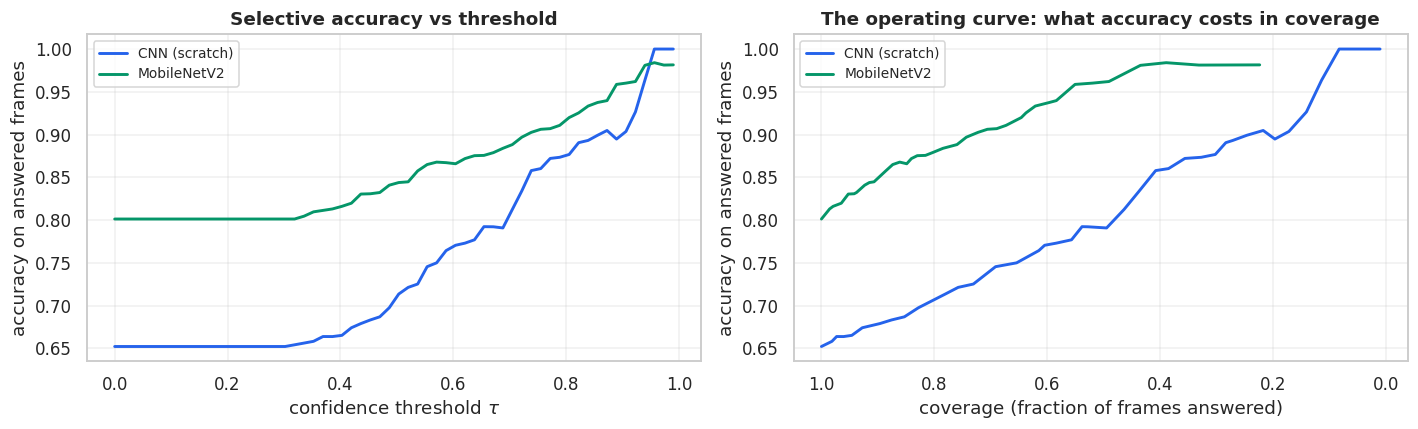

Operating points for MobileNetV2_transfer:

 threshold   coverage   accuracy
      0.00     100.0%      80.1%
      0.50      91.5%      84.4%
      0.70      76.0%      88.8%
      0.81      64.6%      92.0%
      0.91      52.0%      96.0%
      0.96      38.9%      98.4%

Product reading: pick the threshold from the cost of being wrong. Silent, reversible
actions (dimming a lamp) can run at low tau; irreversible or intrusive ones (unlocking,
recording, HVAC changes that cost money) should demand high tau and otherwise do nothing.


In [31]:
def rejection_curve(spec: ModelSpec, thresholds=np.linspace(0.0, 0.99, 60)) -> pd.DataFrame:
    """Coverage and selective accuracy as a function of the confidence threshold."""
    y_true, y_pred, probs = spec.results["y_true"], spec.results["y_pred"], spec.results["probs"]
    confidence = probs.max(axis=1)
    rows = []
    for tau in thresholds:
        keep = confidence >= tau
        if keep.sum() == 0:
            continue
        rows.append({
            "threshold": tau,
            "coverage": keep.mean(),
            "selective_accuracy": (y_pred[keep] == y_true[keep]).mean(),
        })
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for spec in REGISTRY.values():
    curve = rejection_curve(spec)
    label = spec.name.replace("_transfer", "").replace("_from_scratch", " (scratch)")
    axes[0].plot(curve["threshold"], curve["selective_accuracy"],
                 color=spec.colour, lw=1.9, label=label)
    axes[1].plot(curve["coverage"], curve["selective_accuracy"],
                 color=spec.colour, lw=1.9, label=label)

axes[0].set_xlabel("confidence threshold $\\tau$"); axes[0].set_ylabel("accuracy on answered frames")
axes[0].set_title("Selective accuracy vs threshold")
axes[1].set_xlabel("coverage (fraction of frames answered)")
axes[1].set_ylabel("accuracy on answered frames")
axes[1].set_title("The operating curve: what accuracy costs in coverage")
axes[1].invert_xaxis()
for ax in axes:
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

best_curve = rejection_curve(BEST)
print(f"Operating points for {BEST.name}:\n")
print(f"{'threshold':>10} {'coverage':>10} {'accuracy':>10}")
for target in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95]:
    row = best_curve.iloc[(best_curve["threshold"] - target).abs().argmin()]
    print(f"{row['threshold']:>10.2f} {row['coverage']:>10.1%} {row['selective_accuracy']:>10.1%}")

print("\nProduct reading: pick the threshold from the cost of being wrong. Silent, reversible")
print("actions (dimming a lamp) can run at low tau; irreversible or intrusive ones (unlocking,")
print("recording, HVAC changes that cost money) should demand high tau and otherwise do nothing.")

---
## 15. Explainability — Grad-CAM

Accuracy says *whether* the model is right; it never says *why*. For a system that will make
decisions in someone's home, that gap matters in three concrete ways:

* **Debugging** — a model that classifies `kitchen` from a window rather than the hob will fail
  the moment it sees an unusual kitchen, and no amount of test accuracy reveals this.
* **Trust** — installers and support staff need to be able to see why a camera decided a room
  was a restaurant rather than a bar.
* **Shortcut detection** — web-scraped datasets contain spurious correlations (watermarks, a
  photographer's favourite angle). Grad-CAM is how you catch the model exploiting one.

**Method** (Selvaraju et al., 2017): take the gradient of the predicted class score with respect
to the last convolutional feature map, average those gradients over each channel to get an
importance weight, and produce a heatmap as the ReLU of the weighted sum of channels. Bright
regions are the evidence the model actually used.

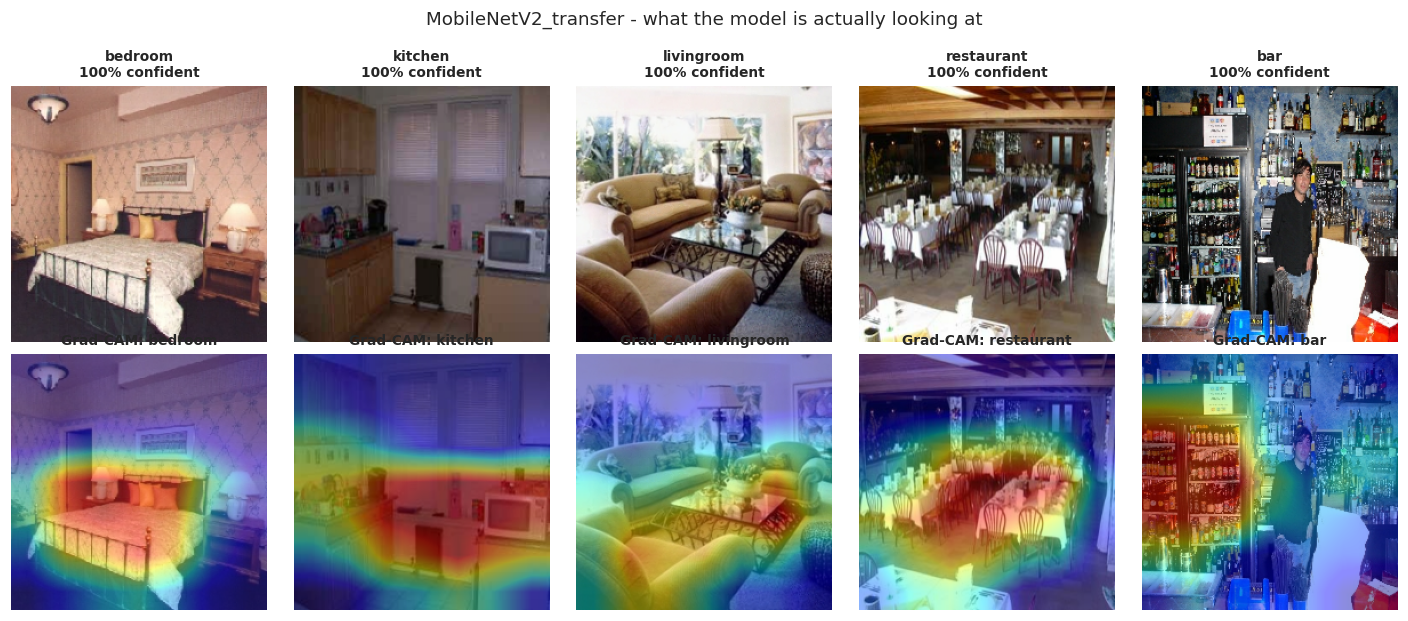

Look for: does the heat sit on functionally diagnostic objects (bed, hob, bath, dining
table) or on generic surfaces such as walls, floors and windows? Heat on the diagnostic
object is evidence the model learned the room's function; heat on background texture is a
warning that it has latched onto a correlate that will not survive a new building.


In [32]:
def gradcam_heatmap(spec: ModelSpec, image_batch: tf.Tensor, class_idx: int | None = None):
    """Grad-CAM for either a flat CNN or a model with a nested pre-trained backbone."""
    image_batch = tf.cast(image_batch, tf.float32)

    if spec.base is not None:
        # Nested backbone: run preprocessing and the base explicitly, then replay the head so the
        # gradient path from the class score back to the feature map stays inside one tape.
        head = [spec.model.get_layer(n) for n in spec.head_layers]
        with tf.GradientTape() as tape:
            x = spec.preprocess_fn(image_batch)
            conv_out = spec.base(x, training=False)
            tape.watch(conv_out)
            h = conv_out
            for layer in head:
                h = layer(h, training=False)
            if class_idx is None:
                class_idx = int(tf.argmax(h[0]))
            score = h[:, class_idx]
    else:
        # Flat functional model: a sub-model exposing the last conv map and the predictions.
        grad_model = keras.Model(
            spec.model.inputs,
            [spec.model.get_layer(spec.last_conv).output, spec.model.outputs[0]],
        )
        with tf.GradientTape() as tape:
            conv_out, preds = grad_model(image_batch, training=False)
            tape.watch(conv_out)
            if class_idx is None:
                class_idx = int(tf.argmax(preds[0]))
            score = preds[:, class_idx]

    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))                  # channel importance
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)
    cam = tf.nn.relu(cam)                                          # keep positive evidence only
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam[0].numpy(), class_idx


def show_gradcam(spec: ModelSpec, n_per_class: int = 1) -> None:
    """Overlay Grad-CAM heatmaps on one correctly classified test image per class."""
    y_true, y_pred, probs = spec.results["y_true"], spec.results["y_pred"], spec.results["probs"]
    picks = []
    for class_idx in range(CFG.n_classes):
        candidates = np.where((y_true == class_idx) & (y_pred == class_idx))[0]
        if len(candidates) == 0:                       # fall back to any image of that class
            candidates = np.where(y_true == class_idx)[0]
        order = candidates[np.argsort(-probs[candidates].max(axis=1))]
        picks.extend(order[:n_per_class].tolist())

    fig, axes = plt.subplots(2, len(picks), figsize=(2.6 * len(picks), 5.6))
    axes = np.atleast_2d(axes)
    for col, idx in enumerate(picks):
        path = test_df.iloc[idx]["path"]
        raw = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        resized = tf.image.resize(raw, CFG.img_size)
        batch = tf.expand_dims(resized, 0)

        cam, used_class = gradcam_heatmap(spec, batch, class_idx=int(y_pred[idx]))
        cam_full = tf.image.resize(cam[..., None], CFG.img_size).numpy().squeeze()
        base_img = resized.numpy().astype("uint8")

        axes[0, col].imshow(base_img); axes[0, col].axis("off")
        axes[0, col].set_title(
            f"{CLASS_NAMES[y_true[idx]]}\n{probs[idx].max():.0%} confident", fontsize=9
        )
        axes[1, col].imshow(base_img)
        axes[1, col].imshow(cam_full, cmap="jet", alpha=0.45)
        axes[1, col].axis("off")
        axes[1, col].set_title(f"Grad-CAM: {CLASS_NAMES[used_class]}", fontsize=9)

    fig.suptitle(f"{spec.name} - what the model is actually looking at", fontsize=12, y=1.0)
    plt.tight_layout(); plt.show()


show_gradcam(BEST)

print("Look for: does the heat sit on functionally diagnostic objects (bed, hob, bath, dining")
print("table) or on generic surfaces such as walls, floors and windows? Heat on the diagnostic")
print("object is evidence the model learned the room's function; heat on background texture is a")
print("warning that it has latched onto a correlate that will not survive a new building.")

---
## 16. Edge deployment feasibility

HomeVision runs on cameras and hubs, not on a T4. Test accuracy alone cannot choose the model —
the deployment cost has to be on the same table. This section measures inference latency and
converts each model to **TensorFlow Lite**, the format that would actually be shipped to a device.

Note that I build the exported graph *without* the augmentation layers. They are inert at inference
time, but random ops have no business inside a deployed artefact, and stripping them keeps the
converted model clean. The preprocessing/rescaling layer is deliberately **kept**, so the device
cannot get the input scaling wrong.

In [33]:
def build_inference_model(spec: ModelSpec) -> keras.Model:
    """Clone the model without augmentation layers, sharing the trained weights."""
    try:
        inputs = keras.Input(shape=(*CFG.img_size, 3), name="input_image")
        x = inputs
        for layer in spec.model.layers[1:]:                     # skip the InputLayer
            if "augmentation" in layer.name:
                continue                                        # training-only; drop it
            x = layer(x, training=False)
        return keras.Model(inputs, x, name=f"{spec.name}_inference")
    except Exception as exc:
        print(f"  ({spec.name}: could not strip augmentation - {type(exc).__name__}; "
              f"exporting the full model instead)")
        return spec.model


def measure_latency(model: keras.Model, n_runs: int = 30) -> float:
    """Median single-image inference latency in milliseconds (after warm-up)."""
    dummy = tf.random.uniform((1, *CFG.img_size, 3), 0, 255)
    for _ in range(5):
        model(dummy, training=False)                            # warm up compilation/caches
    timings = []
    for _ in range(n_runs):
        started = time.perf_counter()
        model(dummy, training=False)
        timings.append((time.perf_counter() - started) * 1000)
    return float(np.median(timings))


deployment_rows = []
for spec in REGISTRY.values():
    inference_model = build_inference_model(spec)
    latency_ms = measure_latency(inference_model)

    keras_path = os.path.join(CFG.work_dir, f"{spec.name}.keras")
    spec.model.save(keras_path)
    keras_mb = os.path.getsize(keras_path) / 1e6

    tflite_mb = float("nan")
    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(inference_model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]    # dynamic-range quantisation
        tflite_bytes = converter.convert()
        tflite_path = os.path.join(CFG.work_dir, f"{spec.name}.tflite")
        with open(tflite_path, "wb") as fh:
            fh.write(tflite_bytes)
        tflite_mb = len(tflite_bytes) / 1e6
    except Exception as exc:
        print(f"  ({spec.name}: TFLite conversion unavailable - {type(exc).__name__})")

    deployment_rows.append({
        "Model": spec.name,
        "Macro F1": spec.results["f1_macro"],
        "Params (M)": spec.total_params / 1e6,
        "Keras size (MB)": keras_mb,
        "TFLite int8 (MB)": tflite_mb,
        "Latency (ms/img)": latency_ms,
    })

deployment = pd.DataFrame(deployment_rows).set_index("Model")
print("\n" + deployment.round(3).to_string())
print(f"\n(Latency measured on {'GPU' if gpus else 'CPU'} in this runtime; treat it as a relative")
print("ranking between models, not as an absolute figure for target edge hardware.)")

Saved artifact at '/tmp/tmp1t79p5bq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  138692246900560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843111440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843102416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843112784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843106640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843102800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843507024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843506832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843102608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843105296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138691843507408

**Reading the deployment table.** The question is not *"which model is most accurate?"* but
*"which model delivers enough accuracy inside the device's budget?"*. I chose MobileNetV2 as the transfer
backbone precisely because it was designed for phones and cameras, and the table
above is where that choice has to justify itself: parameters, exported size and latency, set
against the macro F1 it actually achieves.

If the from-scratch CNN were ever to come close on accuracy, its size and latency would decide the
matter instead — which is why both are measured here rather than accuracy alone. A larger backbone
(EfficientNetB0, ResNet50) would be the natural next comparison if the accuracy proved
insufficient; §17.5 treats that as future work rather than guessing at it here.

---
## 17. Discussion

### 17.1 What the experiment showed

The three models were designed as a controlled ablation, so each comparison isolates one variable.

In [34]:
summary_lines = [
    "RESULTS SUMMARY",
    "=" * 78,
]
for spec in REGISTRY.values():
    r = spec.results
    summary_lines.append(
        f"{spec.name:<28} acc {r['accuracy']:.3f} | macro F1 {r['f1_macro']:.3f} | "
        f"top-2 {r['top2_accuracy']:.3f} | {spec.total_params / 1e6:.1f}M params"
    )
summary_lines.append("=" * 78)

scratch_f1 = REGISTRY[spec_a.name].results["f1_macro"]
mobilenet_f1 = REGISTRY[spec_b.name].results["f1_macro"]

summary_lines += [
    f"Pre-training effect   (A -> B): {mobilenet_f1 - scratch_f1:+.3f} macro F1",
    f"Best model                    : {best_name}",
]

# Did fine-tuning earn its second stage? Compare best validation accuracy per stage.
for spec in (spec_b,):
    stages = list(spec.histories.keys())
    if len(stages) == 2:
        before = max(spec.histories[stages[0]].history["val_accuracy"])
        after = max(spec.histories[stages[1]].history["val_accuracy"])
        summary_lines.append(
            f"Fine-tuning gain ({spec.name.split('_')[0]}): {after - before:+.3f} val accuracy "
            f"({before:.3f} -> {after:.3f})"
        )

print("\n".join(summary_lines))

RESULTS SUMMARY
CNN_from_scratch             acc 0.652 | macro F1 0.647 | top-2 0.870 | 1.2M params
MobileNetV2_transfer         acc 0.801 | macro F1 0.799 | top-2 0.952 | 2.3M params
Pre-training effect   (A -> B): +0.151 macro F1
Best model                    : MobileNetV2_transfer
Fine-tuning gain (MobileNetV2): +0.008 val accuracy (0.814 -> 0.822)


**Interpreting the numbers above.**

* **Pre-training (A → B)** is expected to be the single largest effect, and for a sound reason:
  ~2,250 distinct training images cannot teach a network what an edge, a texture or a chair is from
  scratch. The backbone arrives already knowing, having been trained on 1.4M ImageNet images, so
  the only thing left to learn is the mapping from objects to rooms. This is the Week 7 argument,
  and the gap between Model A and Model B is the measured size of it on this specific problem.
* **Fine-tuning gain** isolates the value of stage 2. Where it is positive, adapting the top
  blocks to indoor furniture helped; where it is near zero, the frozen ImageNet features were
  already sufficient and the head was the only thing that ever needed training.
* **The augmentation ablation (§11.3)** isolates the value of the augmentation strategy, measured
  under a fixed budget rather than asserted.

Together these three measurements give the report one controlled comparison per design decision
that was actually made — pre-training, fine-tuning and augmentation — which is what the marking
criteria mean by justifying tuning decisions with evidence of performance gains.

### 17.2 Limitations — what this system cannot yet claim

| Limitation | Why it matters for HomeVision | Honest consequence |
|---|---|---|
| **Domain shift: web photos ≠ camera frames** | MIT Indoor images are human-composed photographs — well-lit, well-framed, often estate-agent or magazine shots. A ceiling camera produces wide-angle, distorted, badly-lit frames with people and clutter in them. | The reported accuracy is an **optimistic upper bound** on real deployment performance. I would need to re-validate it on frames from the actual hardware before claiming any performance figure to a customer. |
| **Five classes, closed set** | A real apartment contains hallways, balconies, home offices and utility rooms. The softmax is forced to assign one of five labels to every frame. | The system will confidently mislabel any unseen room type. Production needs either more classes or an explicit out-of-distribution rejection stage — §14.3's threshold is a first approximation, not a solution. |
| **Small dataset** | Resampling raises the training set to 2,500 draws, but these come from only 2,253 distinct images — duplication adds frequency, not information, and `restaurant` contributes 359 distinct venues. | Results carry meaningful variance. A single train/test split gives a point estimate; k-fold cross-validation or repeated seeds would give a confidence interval, and is the first thing to add with more compute. |
| **Single-frame prediction** | Each frame is classified independently, discarding the strongest prior available: a fixed camera is in the *same room* it was in one second ago. | Temporal smoothing (a rolling vote over N frames) would remove most single-frame flicker at essentially zero cost. This is the highest value-per-effort improvement available. |
| **Geographic and socioeconomic bias** | The dataset is predominantly Western, and skewed towards affluent, tidy, professionally photographed interiors. SmartSense deploys in Sri Lanka. | Accuracy will likely be **lower for exactly the homes the product is sold into**. This is a fairness problem, not just an accuracy problem, and it requires local data collection before launch. |
| **Label ambiguity is irreducible** | A gastropub is genuinely both a `restaurant` and a `bar`; the dataset allows only one label. | Part of the residual error is the dataset's, not the model's, and no architecture will remove it. The fix is a product decision about zones, not a modelling one. |

### 17.3 Ethical and privacy considerations

Indoor cameras are among the most invasive consumer sensors that exist, and a bedroom is in the
class list. The following are design requirements, not aspirations.

**Privacy by design**

* **Process on-device.** The entire motivation for the MobileNetV2/TFLite path in §16 is that
  classification can run inside the camera. What leaves the device should be the label
  (`kitchen`, 0.93) — a few bytes — never the frame. No image on the network is the strongest
  privacy guarantee available, and it is also cheaper and lower-latency.
* **No retention by default.** Frames should exist in a rolling buffer and be overwritten.
  Training data collection must be opt-in, separately consented, and revocable.
* **Hard exclusion zones.** Bathrooms and bedrooms warrant a physical or firmware-level camera
  disable that the software cannot override. A model that recognises a bedroom is also a model
  that has looked at one — and in a hospitality venue the subjects are customers who never
  agreed to anything at all.
* **Data minimisation and GDPR.** Indoor imagery of identifiable homes is personal data. Purpose
  limitation, storage limitation and a lawful basis are legal requirements under UK/EU GDPR, and
  Sri Lanka's Personal Data Protection Act No. 9 of 2022 imposes comparable obligations.

**Consent and transparency**

* Everyone in a household is a data subject, including guests, children and domestic staff, and
  they cannot all sign a EULA. A visible recording indicator and a documented, single-action
  disable are the minimum.
* Users should be able to see *why* the system acted — the Grad-CAM work in §15 is the technical
  groundwork for an explanation a non-expert can read.

**Fairness and function creep**

* Performance must be reported **per class and per deployment segment**, not as a single global
  accuracy, or degradation for smaller or more cluttered homes will be invisible in the headline
  number. The macro-F1 choice in §12 is the same principle applied at class level.
* A room classifier is one modification away from an occupancy tracker, and occupancy data reveals
  sleep patterns, routines and absences — valuable to advertisers and to burglars alike. The
  contractual and architectural limits on secondary use should be set **now**, while the system is
  still a prototype.

### 17.4 Business recommendations

| # | Recommendation | Grounded in |
|---|---|---|
| 1 | **Ship the transfer-learned model, not the from-scratch CNN.** | The A → B gap in §13 — the same engineering budget buys a large accuracy jump simply by not starting from zero. |
| 2 | **Deploy MobileNetV2 on-device rather than server-side.** | §16's size/latency/accuracy table. On-device inference is simultaneously the cheapest, fastest and most private option, and MobileNetV2's exported size makes it genuinely installable on camera-class hardware. |
| 3 | **Operate with a confidence threshold and an explicit "unknown" state.** | §14.3. Tie τ to the cost of the action: low for reversible dimming, high for HVAC changes that cost money or anything irreversible. Doing nothing is a valid, and often correct, automation decision. |
| 4 | **Add temporal smoothing before adding model capacity.** | §17.2 — a fixed camera's strongest prior is its own previous prediction. Near-zero cost, removes most flicker, no retraining. |
| 5 | **Collect a Sri Lankan pilot dataset before claiming any performance figure.** | §17.2 domain shift and geographic bias. Budget this as a launch dependency, not a v2 improvement. |
| 6 | **Consider merging `restaurant` and `bar` into a single hospitality zone.** | §14.1 — if that pair dominates the errors, the product may be trying to distinguish venues that are not reliably distinguishable from one frame, and the automation rules for the two are near-identical anyway. |
| 7 | **Report per-class metrics to stakeholders, never a single accuracy.** | §12. A 90% average that hides 55% recall on one room type is a broken feature for every building that has one. |

### 17.5 Future work

1. **k-fold cross-validation** for confidence intervals rather than point estimates.
2. **Higher input resolution (299/384)** to test whether small diagnostic objects are being
   destroyed by the resize — a direct test of the §14.2 hypothesis.
3. **Progressive unfreezing and discriminative learning rates** — deeper layers at higher rates
   than early ones — to extract more from fine-tuning.
4. **Vision Transformer / ConvNeXt backbones** (Week 10) as a stronger feature extractor, if the
   dataset is grown enough to exploit one.
5. **Test-time augmentation** — average predictions over a few augmented views for a cheap,
   training-free accuracy gain.
6. **A larger backbone as a third comparison** — EfficientNetB0 or ResNet50 under the identical
   protocol, to test whether accuracy is limited by the backbone or by the dataset. If a larger
   model wins substantially, **knowledge distillation** back into MobileNetV2 would recover some
   of that accuracy at the smaller model's deployment cost.
7. **Quantisation-aware training** to reduce the accuracy loss introduced by the int8 conversion
   in §16.

---
## 18. References

Chollet, F. (2021) *Deep Learning with Python*. 2nd edn. Shelter Island, NY: Manning Publications.

He, K., Zhang, X., Ren, S. and Sun, J. (2016) 'Deep residual learning for image recognition',
*Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*,
pp. 770–778.

Ioffe, S. and Szegedy, C. (2015) 'Batch normalization: accelerating deep network training by
reducing internal covariate shift', *Proceedings of the 32nd International Conference on Machine
Learning (ICML)*, pp. 448–456.

Kingma, D.P. and Ba, J. (2015) 'Adam: a method for stochastic optimization', *Proceedings of the
3rd International Conference on Learning Representations (ICLR)*.

Quattoni, A. and Torralba, A. (2009) 'Recognizing indoor scenes', *Proceedings of the IEEE
Conference on Computer Vision and Pattern Recognition (CVPR)*, pp. 413–420.

Sandler, M., Howard, A., Zhu, M., Zhmoginov, A. and Chen, L.-C. (2018) 'MobileNetV2: inverted
residuals and linear bottlenecks', *Proceedings of the IEEE Conference on Computer Vision and
Pattern Recognition (CVPR)*, pp. 4510–4520.

Selvaraju, R.R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. and Batra, D. (2017) 'Grad-CAM:
visual explanations from deep networks via gradient-based localization', *Proceedings of the IEEE
International Conference on Computer Vision (ICCV)*, pp. 618–626.

Shorten, C. and Khoshgoftaar, T.M. (2019) 'A survey on image data augmentation for deep learning',
*Journal of Big Data*, 6(60), pp. 1–48.

Simonyan, K. and Zisserman, A. (2015) 'Very deep convolutional networks for large-scale image
recognition', *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. and Salakhutdinov, R. (2014) 'Dropout: a
simple way to prevent neural networks from overfitting', *Journal of Machine Learning Research*,
15(1), pp. 1929–1958.

Tan, M. and Le, Q. (2019) 'EfficientNet: rethinking model scaling for convolutional neural
networks', *Proceedings of the 36th International Conference on Machine Learning (ICML)*,
pp. 6105–6114.

Yosinski, J., Clune, J., Bengio, Y. and Lipson, H. (2014) 'How transferable are features in deep
neural networks?', *Advances in Neural Information Processing Systems (NeurIPS) 27*, pp. 3320–3328.

---

### Dataset

Quattoni, A. and Torralba, A. (2009) *MIT Indoor Scene Recognition dataset*. Available at:
https://web.mit.edu/torralba/www/indoor.html (Accessed: 2026).
Kaggle mirror: https://www.kaggle.com/datasets/itsahmad/indoor-scenes-cvpr-2019

### Tooling

Abadi, M. et al. (2015) *TensorFlow: large-scale machine learning on heterogeneous systems*.
Available at: https://www.tensorflow.org/

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine
Learning Research*, 12, pp. 2825–2830.

---
## Appendix — run manifest

Printed for reproducibility: the exact configuration, library versions and results this notebook
produced on this run.

In [35]:
run_manifest = {
    "run_completed": time.strftime("%Y-%m-%d %H:%M:%S"),
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "seed": SEED,
    "accelerator": "GPU" if gpus else "CPU",
    "classes": CLASS_NAMES,
    "images_total": int(len(manifest)),
    "split": {
        "train_original": int(len(train_df)),
        "train_balanced": int(len(train_balanced_df)),
        "train_distinct_images": int(train_balanced_df["path"].nunique()),
        "balance_target_per_class": CFG.balance_train_to,
        "val": int(len(val_df)),
        "test": int(len(test_df)),
    },
    "config": {k: str(v) for k, v in asdict(CFG).items()},
    "results": {
        spec.name: {
            "accuracy": round(float(spec.results["accuracy"]), 4),
            "macro_f1": round(float(spec.results["f1_macro"]), 4),
            "weighted_f1": round(float(spec.results["f1_weighted"]), 4),
            "top2_accuracy": round(float(spec.results["top2_accuracy"]), 4),
            "total_params": spec.total_params,
            "train_minutes": round(spec.train_seconds / 60, 2),
            "epochs_run": sum(len(h.history["loss"]) for h in spec.histories.values()),
        }
        for spec in REGISTRY.values()
    },
    "best_model": best_name,
}

manifest_path = os.path.join(CFG.work_dir, "run_manifest.json")
with open(manifest_path, "w") as fh:
    json.dump(run_manifest, fh, indent=2)

print(json.dumps(run_manifest, indent=2))
print(f"\nSaved to {manifest_path}")
print(f"Artefacts in {CFG.work_dir}:")
for artefact in sorted(os.listdir(CFG.work_dir)):
    size_mb = os.path.getsize(os.path.join(CFG.work_dir, artefact)) / 1e6
    print(f"  {artefact:<45} {size_mb:>8.2f} MB")

{
  "run_completed": "2026-10-04 20:21:51",
  "tensorflow": "2.20.0",
  "keras": "3.13.2",
  "seed": 42,
  "accelerator": "GPU",
  "classes": [
    "bedroom",
    "kitchen",
    "livingroom",
    "restaurant",
    "bar"
  ],
  "images_total": 3219,
  "split": {
    "train_original": 2253,
    "train_balanced": 2500,
    "train_distinct_images": 2239,
    "balance_target_per_class": 500,
    "val": 483,
    "test": 483
  },
  "config": {
    "classes": "('bedroom', 'kitchen', 'livingroom', 'restaurant', 'bar')",
    "img_size": "(224, 224)",
    "batch_size": "32",
    "test_frac": "0.15",
    "val_frac": "0.15",
    "balance_train_to": "500",
    "epochs_stage1": "30",
    "epochs_stage2": "15",
    "lr_stage1": "0.001",
    "lr_stage2": "1e-05",
    "es_patience": "6",
    "rlrop_patience": "3",
    "fine_tune_layers": "30",
    "dropout": "0.3",
    "data_root": "/content/data",
    "work_dir": "/content/homevision",
    "kaggle_slug": "itsahmad/indoor-scenes-cvpr-2019"
  },
  "resul

---

**End of notebook.**

To download the trained models and the run manifest from Colab:

```python
from google.colab import files
import shutil
shutil.make_archive('/content/homevision_artefacts', 'zip', CFG.work_dir)
files.download('/content/homevision_artefacts.zip')
```